In [ ]:
# -*- coding: utf-8 -*-
# ============================================================
# EDA v2: GPT-2 AI 리뷰 vs 사람 리뷰 (코랩용)
# 연구 질문: 바이럴 마케팅에 쓰이는 AI 리뷰를 모델은 무엇을 보고 잡아내는가?
#           그 기준은 데이터의 차이(EDA)·사람의 통념과 같은가?
#
# 사용법
#   1) 코랩 새 노트북 → 이 파일 전체를 코드 셀 하나에 붙여넣기 → 실행
#      (셀을 나누고 싶으면 "# %%" 표시마다 잘라서 붙여넣기)
#   2) 업로드 창에서 fake reviews dataset CSV 1개 선택
#   3) 약 10분 후 결과 ZIP(EDA_v2_결과.zip)이 자동 다운로드
#
# 결과 파일 중 다음 단계에서 쓰는 것
#   - eda_features.csv : 정제 문장 + 피처 31개 (피처표·모델 단계의 입력)
#   - eda_ranking.csv  : 피처별 효과 크기 순위 (나중에 SHAP 순위와 비교)
# ============================================================

# %% 0. 환경 준비 ---------------------------------------------------
import sys, os, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'vaderSentiment', 'textblob'], check=False)
    subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null 2>&1', shell=True, check=False)

import re, glob, math, html, warnings, zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import FancyBboxPatch
from scipy.stats import spearmanr, mannwhitneyu, norm, chi2_contingency
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40)
try:
    display
except NameError:
    display = print

# 한글 글꼴 (코랩: 나눔고딕, 그 외: 설치된 한글 글꼴 자동 탐색)
KFONT = None
for f in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    if os.path.exists(f):
        font_manager.fontManager.addfont(f)
        plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=f).get_name()
if KFONT is None:
    cands = [p for p in glob.glob('/usr/share/fonts/**/*', recursive=True) + glob.glob('C:/Windows/Fonts/*') + glob.glob('/Library/Fonts/*') + glob.glob('/System/Library/Fonts/*')
             if re.search(r'(Nanum|NotoSansCJK|NotoSansKR|malgun|AppleSDGothic|AppleGothic)', os.path.basename(p), re.I)]
    for p in sorted(cands, key=lambda p: ('Regular' not in p, 'Nanum' not in p)):
        try:
            font_manager.fontManager.addfont(p); plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=p).get_name(); break
        except Exception:
            continue
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 10.5, 'figure.dpi': 110, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#E6ECF2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'text.color': '#3E4C5E', 'axes.labelcolor': '#3E4C5E', 'axes.titlecolor': '#3E4C5E',
                     'xtick.color': '#3E4C5E', 'ytick.color': '#3E4C5E', 'axes.edgecolor': '#9AA6B2',
                     'legend.labelcolor': '#3E4C5E', 'hatch.linewidth': 0.8})

SEED = 42
OUT = Path('eda_v2_results'); OUT.mkdir(exist_ok=True)
AI, HU = 'AI(GPT-2)', '사람'
GROUPS = [AI, HU]
# ---- 색상: 한색 파스텔 + 대비 요소는 블루/로즈 핑크 보색 (색약 구분 기준 통과) ----
COLORS = {AI: '#F2ABAE', HU: '#8DBDEB'}        # 채움색 (파스텔)
EDGE = {AI: '#D9798A', HU: '#4F86B8'}          # 테두리·선·점 (같은 색조, 진하게)
INK, INK2 = '#3E4C5E', '#7A8797'               # 글자 / 보조 글자
GRID = '#E6ECF2'
NEUTRAL, NEUTRAL_EDGE = '#D5DCE4', '#9AA6B2'   # 중립·차이 없음
PERI, PERI_EDGE = '#8F9FE0', '#5E6FBF'         # 페리윙클 (일치·부정 감성 등)
MINT, MINT_EDGE = '#A8D8C8', '#5FA894'         # 민트 (긍정 감성 등)
BOX_FC = '#F4F8FC'                             # 흐름도 상자
from matplotlib.colors import LinearSegmentedColormap
CMAP_DIV = LinearSegmentedColormap.from_list('blue_white_pink', ['#7FB0DD', '#F4F6F8', '#E99AA6'])   # - 파랑 / 0 흰빛 / + 핑크
CMAP_SEQ = LinearSegmentedColormap.from_list('white_blue', ['#F4F8FC', '#6E9FCB'])
DIR_COLORS = {'AI가 큼': (COLORS[AI], EDGE[AI]), '사람이 큼': (COLORS[HU], EDGE[HU]), '차이 작음': (NEUTRAL, NEUTRAL_EDGE)}
BAR_KW = dict(linewidth=1.1)

def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
CAT_KO = {'Home_and_Kitchen': '가정·주방', 'Electronics': '전자제품', 'Clothing_Shoes_and_Jewelry': '의류·신발', 'Sports_and_Outdoors': '스포츠',
          'Books': '도서', 'Toys_and_Games': '장난감', 'Movies_and_TV': '영화·TV', 'Kindle_Store': '전자책', 'Pet_Supplies': '반려동물',
          'Tools_and_Home_Improvement': '공구'}
R_TH = 0.1     # 효과 크기 |r| 기준
CORR_TH = 0.7  # 피처 간 상관 기준

def savefig(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

def export(df_, name, index=True):
    df_.to_csv(OUT / name, encoding='utf-8-sig', index=index); return df_

def rank_biserial(a, b):
    """순위 이연 상관 r. +면 a(AI) 쪽 값이 큼, -면 b(사람) 쪽 값이 큼. -1 ~ +1"""
    a = pd.Series(a).dropna(); b = pd.Series(b).dropna()
    if len(a) == 0 or len(b) == 0: return np.nan
    u = mannwhitneyu(a, b, alternative='two-sided').statistic
    return 2 * u / (len(a) * len(b)) - 1

def spearman_ci(x, y):
    rho = spearmanr(x, y).statistic; n = len(x)
    se = math.sqrt(1.06 / (n - 3)); z = math.atanh(rho)
    return rho, math.tanh(z - 1.96 * se), math.tanh(z + 1.96 * se)

def compare_spearman(r1, n1, r2, n2):
    z = (math.atanh(r1) - math.atanh(r2)) / math.sqrt(1.06 / (n1 - 3) + 1.06 / (n2 - 3))
    return z, 2 * (1 - norm.cdf(abs(z)))

def cramers_v(x, y):
    tab = pd.crosstab(x, y); chi2 = chi2_contingency(tab)[0]; n = tab.values.sum()
    return math.sqrt(chi2 / (n * (min(tab.shape) - 1)))
print('환경 준비 완료 | 코랩:', IN_COLAB, '| 글꼴:', plt.rcParams['font.family'])

환경 준비 완료 | 코랩: True | 글꼴: ['NanumGothic']


Saving fake reviews dataset.csv to fake reviews dataset.csv
불러온 파일: fake reviews dataset.csv


,역할,자료형,고유값 수,결측치,예시
변수,,,,,
category,통제 변수 (상품군 10개),object,10,0,Home_and_Kitchen
rating,통제 변수 (별점 1~5),float64,5,0,5.0
label,"타깃 변수 (CG = AI 작성, OR = 사람 작성)",object,2,0,CG
text_,분석 원천 (여기서 피처를 계산),object,40412,0,"Love this! Well made, sturdy, and very comfor..."


,값
전체 리뷰 수,40432
AI(CG),20216
사람(OR),20216
결측치(전체),0
완전히 같은 행,12
별점 범위,1~5
상품군 수,10


,값
별점 × 라벨 Cramér V,0.0134
상품군 × 라벨 Cramér V,0.0000


→ Cramér V가 0에 가까우면 AI와 사람의 별점·상품군 구성이 같다는 뜻 (구성 차이로 생기는 착시가 없음)


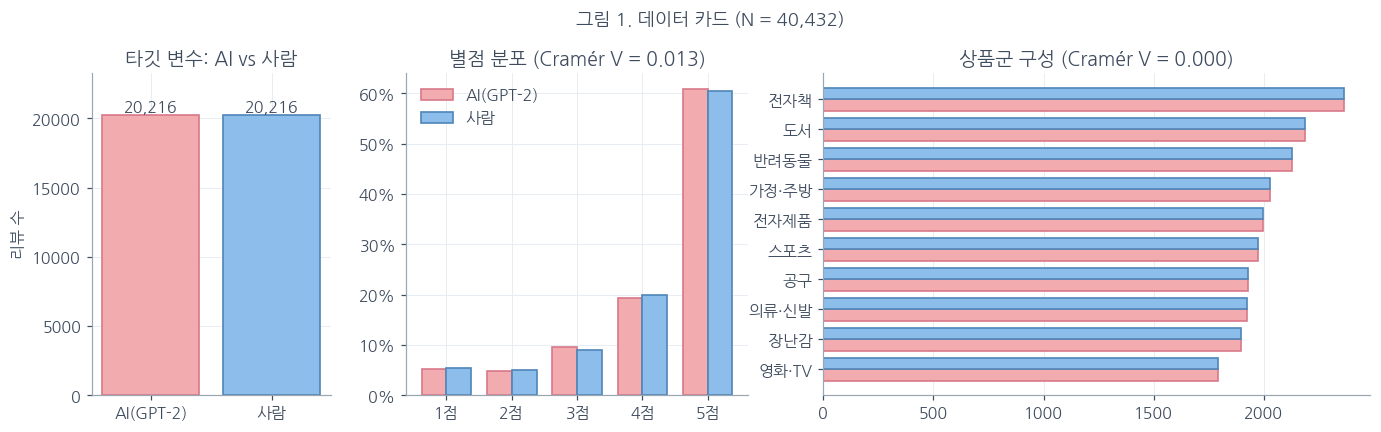

In [ ]:
# %% 1. 데이터 불러오기와 데이터 카드 ---------------------------------
DATA_DIR = Path(os.environ.get('EDA_DATA_DIR', '/content' if IN_COLAB else '.'))
if IN_COLAB:
    from google.colab import files
    files.upload()
csvs = sorted(DATA_DIR.glob('*fake*review*.csv')) or sorted(DATA_DIR.glob('*.csv'))
assert csvs, 'CSV 파일을 찾지 못했어요. fake reviews dataset CSV를 업로드하세요.'
print('불러온 파일:', csvs[0].name)

raw = pd.read_csv(csvs[0])
raw['review_id'] = np.arange(len(raw))
raw['text_'] = raw['text_'].astype(str)
raw['rating'] = pd.to_numeric(raw['rating'], errors='coerce')
raw['category'] = raw['category'].astype(str).str.replace(r'_5$', '', regex=True)
raw['group'] = np.where(raw['label'] == 'CG', AI, HU)

ROLE = {'category': '통제 변수 (상품군 10개)', 'rating': '통제 변수 (별점 1~5)',
        'label': '타깃 변수 (CG = AI 작성, OR = 사람 작성)', 'text_': '분석 원천 (여기서 피처를 계산)'}
card = pd.DataFrame([{'변수': c, '역할': ROLE[c], '자료형': str(raw[c].dtype), '고유값 수': raw[c].nunique(),
                      '결측치': int(raw[c].isna().sum()), '예시': str(raw[c].iloc[0])[:50]} for c in ROLE]).set_index('변수')
display(export(card, '01_데이터카드_변수.csv'))
basic = pd.Series({'전체 리뷰 수': len(raw), 'AI(CG)': int((raw.label == 'CG').sum()), '사람(OR)': int((raw.label == 'OR').sum()),
                   '결측치(전체)': int(raw[list(ROLE)].isna().sum().sum()),
                   '완전히 같은 행': int(raw.duplicated(['category', 'rating', 'label', 'text_']).sum()),
                   '별점 범위': f"{raw.rating.min():.0f}~{raw.rating.max():.0f}", '상품군 수': raw.category.nunique()}, name='값')
display(export(basic.to_frame(), '01_데이터카드_기본.csv'))

ctrl = pd.Series({'별점 × 라벨 Cramér V': cramers_v(raw['rating'], raw['label']),
                  '상품군 × 라벨 Cramér V': cramers_v(raw['category'], raw['label'])}, name='값').round(4)
display(export(ctrl.to_frame(), '01_통제변수_균형.csv'))
print('→ Cramér V가 0에 가까우면 AI와 사람의 별점·상품군 구성이 같다는 뜻 (구성 차이로 생기는 착시가 없음)')

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios': [0.7, 1, 1.6]})
cnt = raw['group'].value_counts().reindex(GROUPS)
axs[0].bar(GROUPS, cnt.values, color=[COLORS[g] for g in GROUPS], edgecolor=[EDGE[g] for g in GROUPS], **BAR_KW)
for i, v in enumerate(cnt.values): axs[0].text(i, v + 300, f'{v:,}', ha='center')
axs[0].set_title('타깃 변수: AI vs 사람'); axs[0].set_ylabel('리뷰 수'); axs[0].set_ylim(0, cnt.max() * 1.15)
tab = pd.crosstab(raw['rating'], raw['group'], normalize='columns')[GROUPS]
x = np.arange(len(tab)); w = 0.38
for i, g in enumerate(GROUPS): axs[1].bar(x + (i - 0.5) * w, tab[g], w, color=COLORS[g], edgecolor=EDGE[g], label=g, **BAR_KW)
axs[1].set_xticks(x, [f'{int(r)}점' for r in tab.index]); axs[1].yaxis.set_major_formatter(PercentFormatter(1))
axs[1].set_title(f'별점 분포 (Cramér V = {ctrl.iloc[0]:.3f})'); axs[1].legend(frameon=False)
tab = pd.crosstab(raw['category'].map(CAT_KO), raw['group'])[GROUPS].sort_values(AI)
y = np.arange(len(tab))
for i, g in enumerate(GROUPS): axs[2].barh(y + (i - 0.5) * w, tab[g], w, color=COLORS[g], edgecolor=EDGE[g], label=g, **BAR_KW)
axs[2].set_yticks(y, tab.index); axs[2].set_title(f'상품군 구성 (Cramér V = {ctrl.iloc[1]:.3f})'); axs[2].grid(axis='y', visible=False)
fig.suptitle(f'그림 1. 데이터 카드 (N = {len(raw):,})', y=1.03, fontsize=12)
savefig(fig, 'fig01_데이터카드.png')

In [ ]:
# %% 2. 원문 진단: 전처리가 왜 필요한가 ------------------------------
# 내용과 상관없는 형식 흔적이 AI/사람 한쪽에만 몰려 있으면 모델이 그 흔적으로 "커닝"한다.
HTML_TAG = re.compile(r'<[^>]+>')
HTML_ENT = re.compile(r'&[a-zA-Z#0-9]+;')
URL_RE = re.compile(r'(https?://\S+|www\.\S+|\S+@\S+\.\w+)')
FOREIGN = {'de', 'la', 'el', 'que', 'en', 'es', 'los', 'las', 'una', 'por', 'para', 'muy', 'con', 'del', 'se', 'lo',
           'le', 'les', 'et', 'est', 'pour', 'une', 'des', 'du', 'sur', 'ce', 'je', 'und', 'der', 'die', 'das', 'ist', 'nicht'}
EN_SW = set(ENGLISH_STOP_WORDS) - FOREIGN

def is_foreign(s):
    toks = re.findall(r'[a-zà-ÿ]+', s.lower())
    f = sum(t in FOREIGN for t in toks); e = sum(t in EN_SW for t in toks)
    return f >= 3 and f > e

def format_flags(t):
    t = t.astype(str)
    return pd.DataFrame({
        '문장부호로 끝나지 않음': ~t.str.strip().str[-1].isin(list('.!?)"\'')),
        '마침표 뒤 띄어쓰기 없음': t.str.contains(r'[a-z]\.[A-Z]'),
        '두 칸 이상 띄어쓰기': t.str.contains('  '),
        '줄바꿈 포함': t.str.contains('\n'),
        'HTML 태그·기호': t.str.contains(HTML_TAG) | t.str.contains(HTML_ENT),
        'URL·이메일': t.str.contains(URL_RE),
        '비영어 리뷰': t.map(is_foreign)}).astype(int)

flags_raw = format_flags(raw['text_'])
flag_tbl = flags_raw.groupby(raw['group']).mean().reindex(GROUPS).T
flag_tbl['차이(AI-사람, %p)'] = 100 * (flag_tbl[AI] - flag_tbl[HU])
display(export(flag_tbl.round(4), '02_원문_형식흔적.csv'))



group,AI(GPT-2),사람,"차이(AI-사람, %p)"
문장부호로 끝나지 않음,0.6481,0.0941,55.3967
마침표 뒤 띄어쓰기 없음,0.2538,0.0000,25.3809
두 칸 이상 띄어쓰기,0.4533,0.3712,8.2113
줄바꿈 포함,0.1693,0.2067,-3.7396
HTML 태그·기호,0.0026,0.0081,-0.5540
URL·이메일,0.0022,0.0032,-0.0989
비영어 리뷰,0.0006,0.0006,0.0000


group,AI(GPT-2),사람,합계
원본,20216,20216,40432
비영어 제거,20205,20204,40409
3단어 미만 제거,20152,20166,40318
라벨 안 중복 제거,20055,20164,40219
AI·사람 양쪽 문장 제거,20054,20163,40217
근사 중복 제거,20052,20162,40214


끝 문장이 잘려서 제거된 비율: AI(GPT-2) 62.6%, 사람 6.7%


원문              정제 후        
group         AI(GPT-2)      사람 AI(GPT-2)      사람
문장부호로 끝나지 않음     0.6481  0.0941    0.0236  0.0362
마침표 뒤 띄어쓰기 없음    0.2538  0.0000    0.0000  0.0011
두 칸 이상 띄어쓰기      0.4533  0.3712    0.0000  0.0000
줄바꿈 포함           0.1693  0.2067    0.0000  0.0000
HTML 태그·기호       0.0026  0.0081    0.0000  0.0000
URL·이메일          0.0022  0.0032    0.0000  0.0000
비영어 리뷰           0.0006  0.0006    0.0000  0.0000

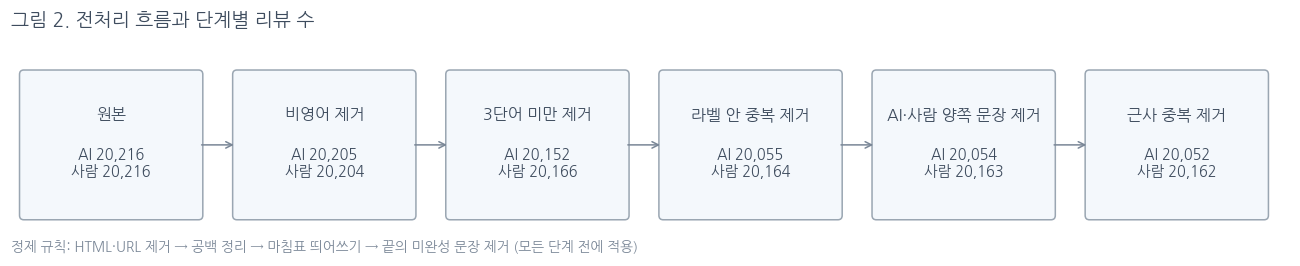

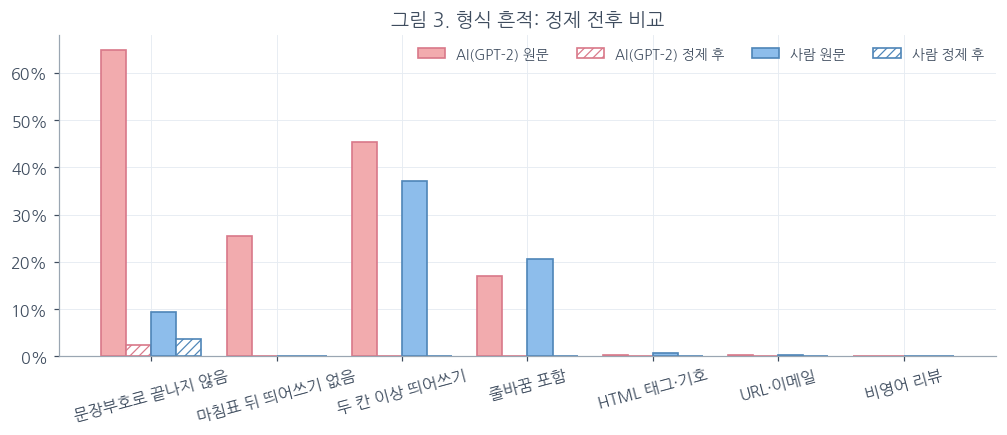

In [ ]:
# %% 3. 정제 (전처리) -------------------------------------------------
END_RE = re.compile(r'[.!?](?=\s|$)')

def clean_text(s):
    """반환: (정제 문장, 끝 문장이 잘렸는지)"""
    s = html.unescape(str(s))
    s = HTML_TAG.sub(' ', s)                           # a. HTML 태그 제거 (아마존 수집 흔적)
    s = URL_RE.sub(' ', s)                             # b. URL·이메일 제거
    s = re.sub(r'\s+', ' ', s).strip()                 # c. 공백·줄바꿈 정리
    s = re.sub(r'([a-z])\.([A-Z])', r'\1. \2', s)      # d. 마침표 뒤 띄어쓰기
    s = re.sub(r' ([.,!?])', r'\1', s)                 # e. 문장부호 앞 공백 제거
    ends = list(END_RE.finditer(s))                    # f. 끝의 미완성 문장 제거
    cut = bool(ends and ends[-1].end() < len(s))
    if cut: s = s[:ends[-1].end()]
    return s, cut

cl = raw['text_'].map(clean_text)
raw['text_clean'] = cl.str[0]; raw['was_truncated'] = cl.str[1]
raw['n_words_clean'] = raw['text_clean'].str.split().str.len()
raw['foreign'] = raw['text_clean'].map(is_foreign)
raw['norm'] = raw['text_clean'].str.lower().str.replace(r'[^a-z0-9 ]', '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

steps = [('원본', raw)]
d = raw[~raw['foreign']];                                   steps.append(('비영어 제거', d))
d = d[d['n_words_clean'] >= 3];                             steps.append(('3단어 미만 제거', d))
d = d.drop_duplicates(['label', 'text_clean']);             steps.append(('라벨 안 중복 제거', d))
conflict = d.groupby('norm')['label'].nunique(); conflict = set(conflict[conflict > 1].index)
d = d[~d['norm'].isin(conflict)];                           steps.append(('AI·사람 양쪽 문장 제거', d))
d = d.drop_duplicates(['label', 'norm']);                   steps.append(('근사 중복 제거', d))
df = d.drop(columns=['norm']).reset_index(drop=True)
step_tbl = pd.DataFrame({n: s['group'].value_counts().reindex(GROUPS) for n, s in steps}).T
step_tbl['합계'] = step_tbl.sum(1)
display(export(step_tbl, '03_정제_단계별_건수.csv'))
trunc = raw.groupby('group')['was_truncated'].mean().reindex(GROUPS)
print('끝 문장이 잘려서 제거된 비율:', ', '.join(f'{g} {v:.1%}' for g, v in trunc.items()))

flags_cln = format_flags(df['text_clean']).groupby(df['group']).mean().reindex(GROUPS).T
ba = pd.concat({'원문': flag_tbl[GROUPS], '정제 후': flags_cln}, axis=1)
display(export(ba.round(4), '03_정제전후_형식흔적.csv'))

# 그림: 전처리 흐름도
fig, ax = plt.subplots(figsize=(15, 2.6)); ax.axis('off'); ax.set_xlim(0, len(steps)); ax.set_ylim(0, 1)
for i, (n, s) in enumerate(steps):
    c = s['group'].value_counts()
    ax.add_patch(FancyBboxPatch((i + 0.06, 0.18), 0.82, 0.64, boxstyle='round,pad=0.02', fc=BOX_FC, ec=NEUTRAL_EDGE))
    ax.text(i + 0.47, 0.64, n, ha='center', va='center', fontsize=10.5, weight='bold')
    ax.text(i + 0.47, 0.42, f'AI {c.get(AI, 0):,}\n사람 {c.get(HU, 0):,}', ha='center', va='center', fontsize=9.5)
    if i: ax.annotate('', xy=(i + 0.06, 0.5), xytext=(i - 0.12, 0.5), arrowprops=dict(arrowstyle='->', color=INK2))
ax.text(0, 0.02, '정제 규칙: HTML·URL 제거 → 공백 정리 → 마침표 띄어쓰기 → 끝의 미완성 문장 제거 (모든 단계 전에 적용)', fontsize=9, color=INK2)
ax.set_title('그림 2. 전처리 흐름과 단계별 리뷰 수', loc='left')
savefig(fig, 'fig02_전처리흐름.png')

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(ba)); w = 0.2
for i, (stage, g) in enumerate([('원문', AI), ('정제 후', AI), ('원문', HU), ('정제 후', HU)]):
    ax.bar(x + (i - 1.5) * w, ba[(stage, g)], w, color=COLORS[g] if stage == '원문' else 'white', label=f'{g} {stage}',
           edgecolor=EDGE[g], hatch='' if stage == '원문' else '////', **BAR_KW)
ax.set_xticks(x, ba.index, rotation=15); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('그림 3. 형식 흔적: 정제 전후 비교'); ax.legend(frameon=False, ncol=4, fontsize=9)
savefig(fig, 'fig03_정제전후_형식흔적.png')

TF-IDF 비교 중 (2~4분)...


,점검,입력,AUC (5겹 교차검증)
0,형식 흔적만 사용 (누수 점검),원문,0.8458
1,형식 흔적만 사용 (누수 점검),정제 후,0.5985
2,TF-IDF + LR,원문,0.9862
3,TF-IDF + LR,정제 후,0.9755
4,TF-IDF + LR,정제 후 + 불용어 제거,0.9480


AI/사람 출현율 차이 상위 50단어 중 불용어: 84% → on, in, you, as, at, to, all, very, or, but, so, when


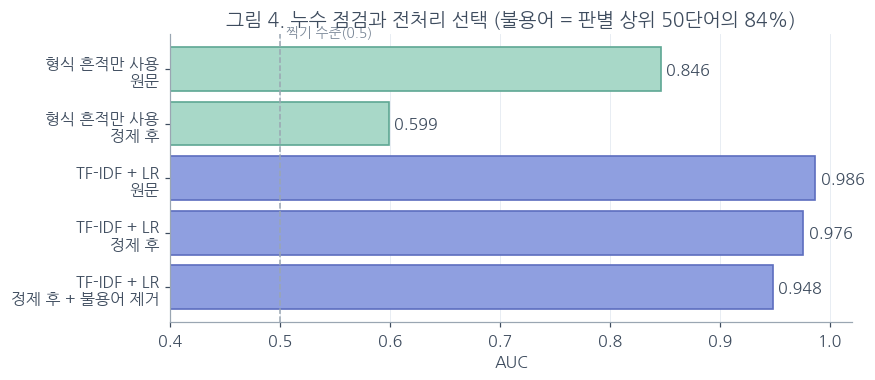

In [ ]:
# %% 4. 누수 점검과 전처리 선택의 근거 ---------------------------------
# (1) 형식 흔적만으로 AI를 맞히는 정도: 정제가 흔적을 지웠는지
# (2) TF-IDF 탐지 성능: 원문 / 정제 / 정제+불용어 제거 → 불용어를 남기는 근거
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

def surface_X(t):
    t = t.astype(str); w = t.str.split().str.len()
    return format_flags(t).drop(columns=['비영어 리뷰']).assign(log_words=np.log1p(w))

y_raw = (raw['label'] == 'CG').values; y_cln = (df['label'] == 'CG').values
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
auc_surf_raw = cross_val_score(lr, surface_X(raw['text_']), y_raw, cv=cv5, scoring='roc_auc').mean()
auc_surf_cln = cross_val_score(lr, surface_X(df['text_clean']), y_cln, cv=cv5, scoring='roc_auc').mean()

def tfidf_auc(texts, y, stop=None):
    m = make_pipeline(TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True, stop_words=stop), LogisticRegression(max_iter=3000, C=4))
    return cross_val_score(m, texts, y, cv=cv5, scoring='roc_auc').mean()
print('TF-IDF 비교 중 (2~4분)...')
auc_tf_raw = tfidf_auc(raw['text_'], y_raw)
auc_tf_cln = tfidf_auc(df['text_clean'], y_cln)
auc_tf_nostop = tfidf_auc(df['text_clean'], y_cln, stop='english')
prep_tbl = pd.DataFrame([
    {'점검': '형식 흔적만 사용 (누수 점검)', '입력': '원문', 'AUC (5겹 교차검증)': auc_surf_raw},
    {'점검': '형식 흔적만 사용 (누수 점검)', '입력': '정제 후', 'AUC (5겹 교차검증)': auc_surf_cln},
    {'점검': 'TF-IDF + LR', '입력': '원문', 'AUC (5겹 교차검증)': auc_tf_raw},
    {'점검': 'TF-IDF + LR', '입력': '정제 후', 'AUC (5겹 교차검증)': auc_tf_cln},
    {'점검': 'TF-IDF + LR', '입력': '정제 후 + 불용어 제거', 'AUC (5겹 교차검증)': auc_tf_nostop}]).round(4)
display(export(prep_tbl, '04_누수점검_전처리비교.csv', index=False))

# 불용어가 판별 단서인지: AI/사람을 가장 잘 가르는 단어 중 불용어 비율
cvb = CountVectorizer(min_df=20, binary=True, token_pattern=r"(?u)\b[a-zA-Z']+\b")
Xb = cvb.fit_transform(df['text_clean']); terms = np.array(cvb.get_feature_names_out())
gap = np.asarray(Xb[y_cln].mean(0)).ravel() - np.asarray(Xb[~y_cln].mean(0)).ravel()
top50 = terms[np.argsort(-np.abs(gap))[:50]]
sw_share = np.mean([t in ENGLISH_STOP_WORDS for t in top50])
print(f'AI/사람 출현율 차이 상위 50단어 중 불용어: {sw_share:.0%} → {", ".join([t for t in top50 if t in ENGLISH_STOP_WORDS][:12])}')

fig, ax = plt.subplots(figsize=(8, 3.4))
labels = [f"{r['점검'].split(' (')[0]}\n{r['입력']}" for _, r in prep_tbl.iterrows()]
bars = ax.barh(labels[::-1], prep_tbl['AUC (5겹 교차검증)'][::-1], color=[PERI] * 3 + [MINT] * 2, edgecolor=[PERI_EDGE] * 3 + [MINT_EDGE] * 2, **BAR_KW)
for b in bars: ax.text(b.get_width() + 0.005, b.get_y() + b.get_height() / 2, f'{b.get_width():.3f}', va='center')
ax.axvline(0.5, color=NEUTRAL_EDGE, ls='--', lw=1); ax.text(0.505, len(labels) - 0.45, '찍기 수준(0.5)', color=INK2, fontsize=9, va='bottom')
ax.set_xlim(0.4, 1.02); ax.set_xlabel('AUC'); ax.grid(axis='y', visible=False)
ax.set_title(f'그림 4. 누수 점검과 전처리 선택 (불용어 = 판별 상위 50단어의 {sw_share:.0%})')
savefig(fig, 'fig04_누수점검_전처리비교.png')

In [ ]:
# %% 5. 피처 계산 ------------------------------------------------------
# 리뷰 1건 → 숫자 피처. 이름 옆 [ ]는 피처 묶음(family).
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
vader = SentimentIntensityAnalyzer()
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+')
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

FIRST_PERSON = {'i', 'me', 'my', 'mine', 'myself', "i'm", "i've", "i'd", "i'll", 'we', 'us', 'our', "we've", "we're"}
SECOND_PERSON = {'you', 'your', 'yours', "you'll", "you're", "you've", 'yourself'}
HYPE = {'best', 'perfect', 'perfectly', 'amazing', 'awesome', 'excellent', 'fantastic', 'wonderful', 'love', 'loved', 'loves',
        'favorite', 'incredible', 'outstanding', 'superb', 'great', 'beautiful', 'brilliant', 'highly', 'absolutely'}
RECOMMEND_RE = re.compile(r"\b(recommend\w*|must[- ]have|must buy|worth (it|the|every)|go for it|you (will|won't|'ll) (love|regret|be)|"
                          r"buy (it|this|one)|don't hesitate|do yourself a favor|five stars|5 stars)\b", re.I)
CLICHE_RE = re.compile(r"\b(great (product|price|quality|item|value|book|read|story|movie|buy)|good (quality|product|value|price|read)|"
                       r"works (great|well|perfectly)|well made|as described|happy with (this|the|my) purchase|exactly what i (wanted|needed))\b", re.I)
DURATION_RE = re.compile(r"\b(for|after|over|in|about|nearly|almost)\s+(a|an|one|two|three|four|five|six|several|few|couple of|\d+)\s+"
                         r"(day|week|month|year)s?\b|\b\d+\s*(days?|weeks?|months?|years?)\b|\b(since|ago|so far)\b", re.I)
PRICE_UNIT_RE = re.compile(r"\$\s?\d|\b\d+(\.\d+)?\s*(inch|inches|in\.|lb|lbs|pounds?|oz|ounces?|mm|cm|ft|feet|foot|qt|gallons?|watts?|hours?|minutes?|mins?|pcs|pack)\b", re.I)
FAMILY_RE = re.compile(r"\b(husband|wife|son|sons|daughter|daughters|kids?|children|child|mom|mother|dad|father|grandson|granddaughter|"
                       r"grandkids|grandchildren|family|boyfriend|girlfriend|sister|brother|baby|toddler)\b", re.I)
CONTRAST_RE = re.compile(r"\b(but|however|although|though|only (complaint|issue|problem|downside|thing)|downside|unfortunately|wish|except)\b", re.I)
NEG_RE = re.compile(r"\b(not|no|never|nothing|none)\b|n't", re.I)
HEDGE_RE = re.compile(r"\b(maybe|perhaps|i think|i guess|kind of|sort of|probably|not sure|seems?)\b", re.I)

def mattr(toks, win=25):
    if len(toks) < win: return len(set(toks)) / max(len(toks), 1)
    return float(np.mean([len(set(toks[i:i + win])) / win for i in range(len(toks) - win + 1)]))

def features(s, rating):
    low = s.lower(); toks = TOKEN_RE.findall(low); n = max(len(toks), 1)
    sents = [x for x in SENT_SPLIT.split(s) if x.strip()]; ns = max(len(sents), 1)
    tri = list(zip(toks, toks[1:], toks[2:]))
    v = vader.polarity_scores(s)['compound']
    sv = [vader.polarity_scores(x)['compound'] for x in sents if len(x.split()) >= 2]
    tb = TextBlob(s).sentiment
    return {
        'n_words': len(s.split()), 'n_sents': len(sents), 'words_per_sent': len(s.split()) / ns,
        'avg_word_len': np.mean([len(t) for t in toks]) if toks else 0.0,
        'ttr40': len(set(toks[:40])) / 40 if len(toks) >= 40 else np.nan,
        'mattr': mattr(toks),
        'rep_trigram': (len(tri) - len(set(tri))) / len(tri) if tri else 0.0,
        'contraction_rate': sum("'" in t for t in toks) / n,
        'commas_per_sent': s.count(',') / ns,
        'allcaps': int(bool(re.search(r'\b[A-Z]{3,}\b', s))),
        'ellipsis': int('...' in s or '…' in s),
        'question': int('?' in s),
        'vader': v,
        'textblob': tb.polarity,
        'subjectivity': getattr(tb, 'subjectivity', np.nan),
        'sent_sd': float(np.std(sv)) if len(sv) > 1 else 0.0,
        'extreme_pos': int(v >= 0.9),
        'star_gap': abs(v - (rating - 3) / 2),
        'exclam_per_sent': s.count('!') / ns,
        'hype_rate': 100 * sum(t in HYPE for t in toks) / n,
        'recommend': int(bool(RECOMMEND_RE.search(s))),
        'cliche': int(bool(CLICHE_RE.search(s))),
        'second_person': sum(t in SECOND_PERSON for t in toks) / n,
        'first_person': sum(t in FIRST_PERSON for t in toks) / n,
        'family': int(bool(FAMILY_RE.search(s))),
        'has_digit': int(bool(re.search(r'\d', s))),
        'duration': int(bool(DURATION_RE.search(s))),
        'price_unit': int(bool(PRICE_UNIT_RE.search(s))),
        'contrast': int(bool(CONTRAST_RE.search(s))),
        'negation': int(bool(NEG_RE.search(low))),
        'hedge': int(bool(HEDGE_RE.search(low))),
    }

# 코드 이름 → (한국어 이름, 묶음, 정의)
FEAT_INFO = {
    'n_words': ('단어 수', '길이·구조', '리뷰 전체 단어 수'),
    'n_sents': ('문장 수', '길이·구조', '마침표·느낌표·물음표 기준 문장 수'),
    'words_per_sent': ('문장당 단어 수', '길이·구조', '단어 수 ÷ 문장 수'),
    'avg_word_len': ('평균 단어 길이', '어휘·문체', '단어당 평균 글자 수'),
    'ttr40': ('어휘 다양성(TTR40)', '어휘·문체', '앞 40단어 중 서로 다른 단어 비율, 40단어 미만은 결측'),
    'mattr': ('어휘 다양성(MATTR)', '어휘·문체', '25단어 창을 옮기며 잰 서로 다른 단어 비율 평균 (짧은 글도 계산)'),
    'rep_trigram': ('반복 3단어 비율', '어휘·문체', '같은 3단어 연쇄가 반복된 비율'),
    'contraction_rate': ('축약형 비율', '어휘·문체', "don't, it's 같은 축약형 단어 비율 (구어체)"),
    'commas_per_sent': ('쉼표/문장', '어휘·문체', '문장당 쉼표 수'),
    'allcaps': ('대문자 강조 포함', '어휘·문체', 'GREAT처럼 3글자 이상 대문자 단어'),
    'ellipsis': ('말줄임표 포함', '어휘·문체', '... 사용'),
    'question': ('물음표 포함', '어휘·문체', '? 사용'),
    'vader': ('글 감성(VADER)', '감성·정합성', 'VADER compound, -1~+1'),
    'textblob': ('글 감성(TextBlob)', '감성·정합성', 'TextBlob polarity, -1~+1'),
    'subjectivity': ('주관성(TextBlob)', '감성·정합성', '0 = 객관적, 1 = 주관적'),
    'sent_sd': ('문장별 감성 변동', '감성·정합성', '문장별 VADER 점수의 표준편차'),
    'extreme_pos': ('과잉 긍정', '감성·정합성', 'VADER ≥ 0.9'),
    'star_gap': ('별점-감성 거리', '감성·정합성', '|VADER - (별점-3)/2|, 클수록 별점과 글이 어긋남'),
    'exclam_per_sent': ('느낌표/문장', '바이럴 표현', '문장당 느낌표 수'),
    'hype_rate': ('과장·최상급 표현', '바이럴 표현', '100단어당 best·perfect·amazing·love 등'),
    'recommend': ('추천·권유 표현', '바이럴 표현', 'recommend, must have, worth it, you will love 등'),
    'cliche': ('상투적 칭찬 문구', '바이럴 표현', 'great product, works great, well made 등'),
    'second_person': ('2인칭(you) 비율', '바이럴 표현', '독자를 부르는 you·your 비율'),
    'first_person': ('1인칭 비율', '구체성·경험', 'I·my·we 등 비율'),
    'family': ('가족 언급', '구체성·경험', 'husband, kids, mom 등'),
    'has_digit': ('숫자 포함', '구체성·경험', '아라비아 숫자'),
    'duration': ('사용 기간 표현', '구체성·경험', 'for 3 months, a year ago, so far 등'),
    'price_unit': ('가격·단위 표현', '구체성·경험', '$20, 5 inches, 2 hours 등'),
    'contrast': ('단점·역접 표현', '구체성·경험', 'but, however, only complaint, wish 등'),
    'negation': ('부정어 포함', '구체성·경험', "not, no, never, n't"),
    'hedge': ('망설임 표현', '구체성·경험', 'maybe, I think, kind of 등'),
}
KO = {k: v[0] for k, v in FEAT_INFO.items()}; FAM = {k: v[1] for k, v in FEAT_INFO.items()}
FEATS = list(FEAT_INFO)

print('피처 계산 중 (감성 분석 포함 3~6분)...')
feat = pd.DataFrame([features(s, r) for s, r in zip(df['text_clean'], df['rating'])], index=df.index)[FEATS]
df = pd.concat([df, feat], axis=1)
is_ai = df['group'] == AI
print('피처', len(FEATS), '개 계산 완료 | 리뷰', len(df), '건')
export(pd.DataFrame([{'코드': k, '이름': v[0], '묶음': v[1], '정의': v[2]} for k, v in FEAT_INFO.items()]), '05_피처정의.csv', index=False)

# 집단별 요약 + 효과 크기
def eff(c): return rank_biserial(df.loc[is_ai, c], df.loc[~is_ai, c])
stat = pd.DataFrame({'이름': [KO[c] for c in FEATS], '묶음': [FAM[c] for c in FEATS],
                     f'{AI} 평균': [df.loc[is_ai, c].mean() for c in FEATS], f'{HU} 평균': [df.loc[~is_ai, c].mean() for c in FEATS],
                     f'{AI} 중앙값': [df.loc[is_ai, c].median() for c in FEATS], f'{HU} 중앙값': [df.loc[~is_ai, c].median() for c in FEATS],
                     '효과크기 r': [eff(c) for c in FEATS]}, index=FEATS)
stat['방향'] = np.select([stat['효과크기 r'] >= R_TH, stat['효과크기 r'] <= -R_TH], ['AI가 큼', '사람이 큼'], '차이 작음')
display(export(stat.round(4), '05_피처_집단별요약.csv'))



피처 계산 중 (감성 분석 포함 3~6분)...
피처 31 개 계산 완료 | 리뷰 40214 건


,이름,묶음,AI(GPT-2) 평균,사람 평균,AI(GPT-2) 중앙값,사람 중앙값,효과크기 r,방향
n_words,단어 수,길이·구조,56.1372,72.9425,30.0000,42.0000,-0.1858,사람이 큼
n_sents,문장 수,길이·구조,5.2718,5.0540,3.0000,3.0000,-0.0764,차이 작음
words_per_sent,문장당 단어 수,길이·구조,10.8755,13.9436,10.2727,13.0000,-0.3037,사람이 큼
avg_word_len,평균 단어 길이,어휘·문체,3.9371,4.2095,3.8519,4.1750,-0.4011,사람이 큼
ttr40,어휘 다양성(TTR40),어휘·문체,0.7248,0.8331,0.7250,0.8250,-0.7262,사람이 큼
mattr,어휘 다양성(MATTR),어휘·문체,0.8501,0.9060,0.8437,0.9040,-0.3666,사람이 큼
rep_trigram,반복 3단어 비율,어휘·문체,0.0332,0.0035,0.0000,0.0000,0.1913,AI가 큼
contraction_rate,축약형 비율,어휘·문체,0.0167,0.0158,0.0000,0.0000,-0.0701,차이 작음
commas_per_sent,쉼표/문장,어휘·문체,0.3084,0.4456,0.0800,0.2857,-0.1567,사람이 큼
allcaps,대문자 강조 포함,어휘·문체,0.0701,0.1668,0.0000,0.0000,-0.0968,차이 작음


,count,mean,std,min,25%,50%,75%,90%,99%,max
group,,,,,,,,,,
AI(GPT-2),20052.0,56.1,62.0,3.0,16.0,30.0,72.0,150.0,266.5,303.0
사람,20162.0,72.9,76.0,3.0,22.0,42.0,92.0,189.0,328.0,372.0


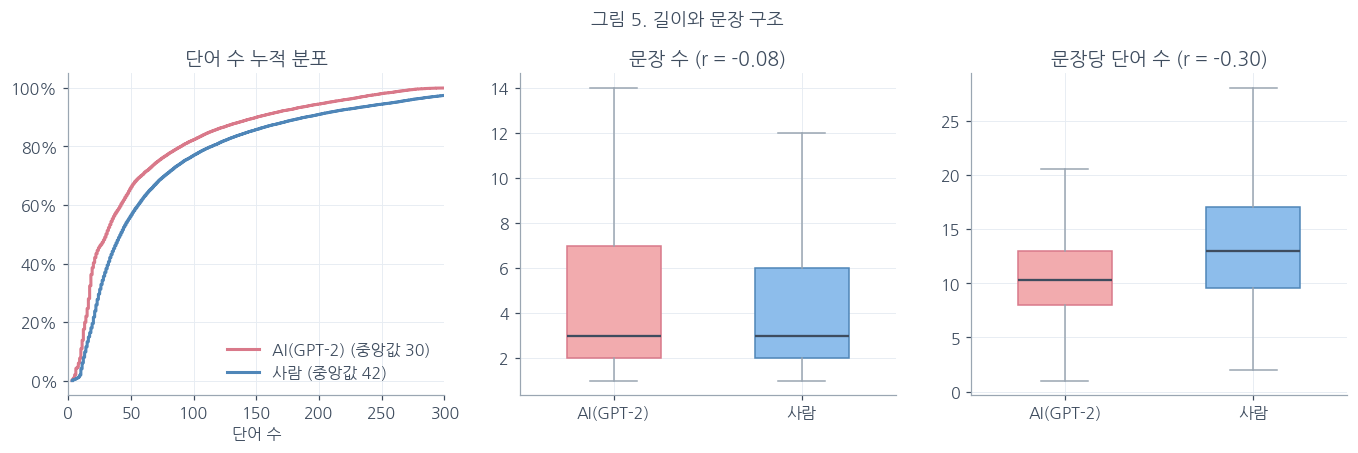

In [ ]:
# %% 6. 길이·구조 ------------------------------------------------------
len_tbl = df.groupby('group')['n_words'].describe(percentiles=[.25, .5, .75, .9, .99]).reindex(GROUPS).round(1)
display(export(len_tbl, '06_길이_요약.csv'))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for g in GROUPS:
    s = np.sort(df.loc[df['group'] == g, 'n_words'].values)
    axs[0].plot(s, np.arange(1, len(s) + 1) / len(s), color=EDGE[g], lw=2, label=f'{g} (중앙값 {np.median(s):.0f})')
axs[0].set_xlim(0, 300); axs[0].set_xlabel('단어 수'); axs[0].yaxis.set_major_formatter(PercentFormatter(1)); axs[0].legend(frameon=False, loc='lower right')
axs[0].set_title('단어 수 누적 분포')
for ax, c, lim in [(axs[1], 'n_sents', 25), (axs[2], 'words_per_sent', 40)]:
    data = [df.loc[df['group'] == g, c].clip(upper=lim) for g in GROUPS]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=NEUTRAL_EDGE), capprops=dict(color=NEUTRAL_EDGE))
    ax.set_xticks([1, 2], GROUPS)
    for p, g in zip(bp['boxes'], GROUPS): p.set_facecolor(COLORS[g]); p.set_edgecolor(EDGE[g])
    ax.set_title(f"{KO[c]} (r = {stat.loc[c, '효과크기 r']:+.2f})")
fig.suptitle('그림 5. 길이와 문장 구조', y=1.03, fontsize=12)
savefig(fig, 'fig05_길이구조.png')

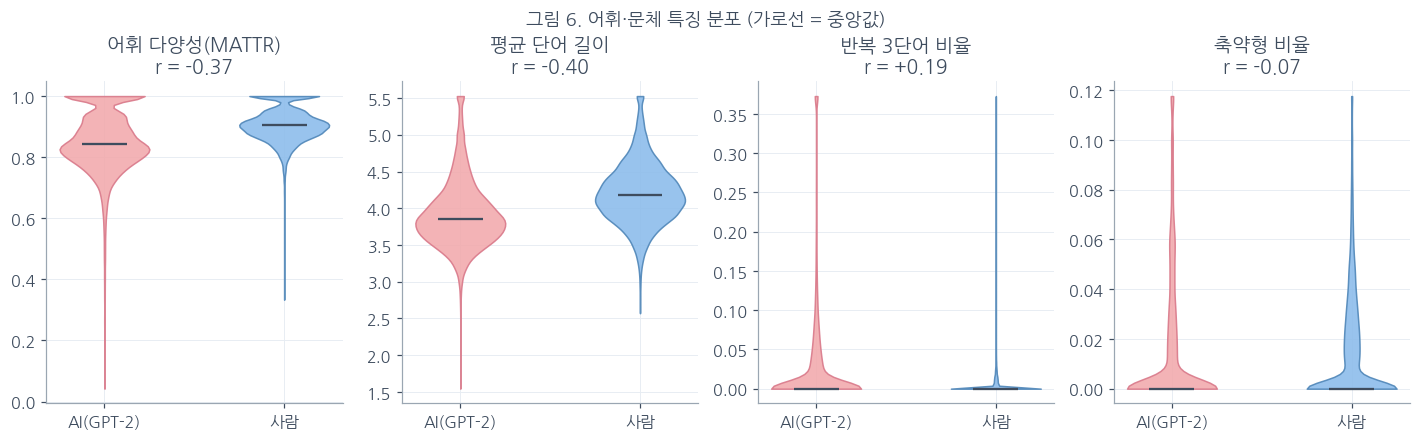

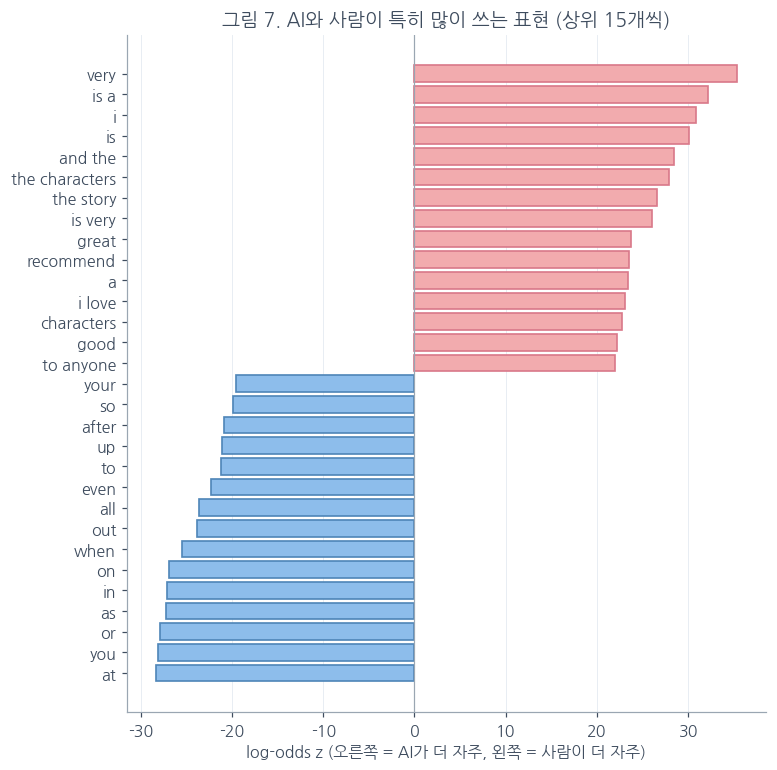

,가장 흔한 첫 단어
group,
AI(GPT-2),"i(20.3%), this(12.1%), the(4.4%), my(3.8%), gr..."
사람,"i(20.5%), this(11.5%), the(4.4%), my(3.9%), gr..."


In [ ]:
# %% 7. 어휘·문체 ------------------------------------------------------
STYLE = ['mattr', 'avg_word_len', 'rep_trigram', 'contraction_rate']
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axs, STYLE):
    data = [df.loc[df['group'] == g, c].dropna() for g in GROUPS]
    hi = np.nanpercentile(pd.concat(data), 99)
    vp = ax.violinplot([d.clip(upper=hi) for d in data], showmedians=True, showextrema=False)
    for b, g in zip(vp['bodies'], GROUPS): b.set_facecolor(COLORS[g]); b.set_edgecolor(EDGE[g]); b.set_alpha(0.9)
    vp['cmedians'].set_color(INK); vp['cmedians'].set_linewidth(1.5)
    ax.set_xticks([1, 2], GROUPS); ax.set_title(f"{KO[c]}\nr = {stat.loc[c, '효과크기 r']:+.2f}")
fig.suptitle('그림 6. 어휘·문체 특징 분포 (가로선 = 중앙값)', y=1.05, fontsize=12)
savefig(fig, 'fig06_어휘문체.png')

# 어느 쪽에 특히 많이 쓰는 단어인가: log-odds (informative Dirichlet prior, Monroe et al. 2008)
cvw = CountVectorizer(ngram_range=(1, 2), min_df=20, token_pattern=r"(?u)\b[a-zA-Z']+\b")
Xw = cvw.fit_transform(df['text_clean']); vocab = np.array(cvw.get_feature_names_out())
ya = np.asarray(Xw[is_ai.values].sum(0)).ravel().astype(float); yh = np.asarray(Xw[~is_ai.values].sum(0)).ravel().astype(float)
alpha = ya + yh; a0 = alpha.sum(); na, nh = ya.sum(), yh.sum()
delta = np.log((ya + alpha) / (na + a0 - ya - alpha)) - np.log((yh + alpha) / (nh + a0 - yh - alpha))
zsc = delta / np.sqrt(1 / (ya + alpha) + 1 / (yh + alpha))
lex = pd.DataFrame({'표현': vocab, 'z': zsc, f'{AI} 빈도': ya.astype(int), f'{HU} 빈도': yh.astype(int)}).sort_values('z')
export(lex, '07_표현_logodds.csv', index=False)
top = pd.concat([lex.head(15), lex.tail(15)])
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.barh(top['표현'], top['z'], color=[COLORS[AI] if v > 0 else COLORS[HU] for v in top['z']],
        edgecolor=[EDGE[AI] if v > 0 else EDGE[HU] for v in top['z']], **BAR_KW)
ax.axvline(0, color=NEUTRAL_EDGE, lw=0.8); ax.grid(axis='y', visible=False)
ax.set_xlabel('log-odds z (오른쪽 = AI가 더 자주, 왼쪽 = 사람이 더 자주)'); ax.set_title('그림 7. AI와 사람이 특히 많이 쓰는 표현 (상위 15개씩)')
savefig(fig, 'fig07_표현_logodds.png')
first = df['text_clean'].str.split().str[0].str.lower().str.strip('".,!?()')
fw = first.groupby(df['group']).apply(lambda s: ', '.join(f'{w}({c / len(s):.1%})' for w, c in Counter(s).most_common(8))).reindex(GROUPS)
display(export(fw.rename('가장 흔한 첫 단어').to_frame(), '07_첫단어.csv'))

,AI(GPT-2),사람
리뷰 수,20052,20162
VADER Spearman,0.046258,0.30565
VADER 95%CI,"[0.032, 0.060]","[0.293, 0.318]"
TextBlob Spearman,0.160815,0.360848
TextBlob 95%CI,"[0.147, 0.175]","[0.348, 0.373]"
1~2점인데 글은 긍정(VADER),0.701833,0.453894
4~5점인데 글은 부정(VADER),0.062453,0.062515
범주 불일치율(VADER),0.276681,0.218332
과잉 긍정(VADER ≥ 0.9),0.373479,0.319958


,도구,AI(GPT-2) 상관,사람 상관,차이(AI-사람),z,p값,p값 표기
0,VADER,0.0463,0.3056,-0.2594,-26.2391,0.0,p < 0.001
1,TextBlob,0.1608,0.3608,-0.2000,-20.9989,0.0,p < 0.001


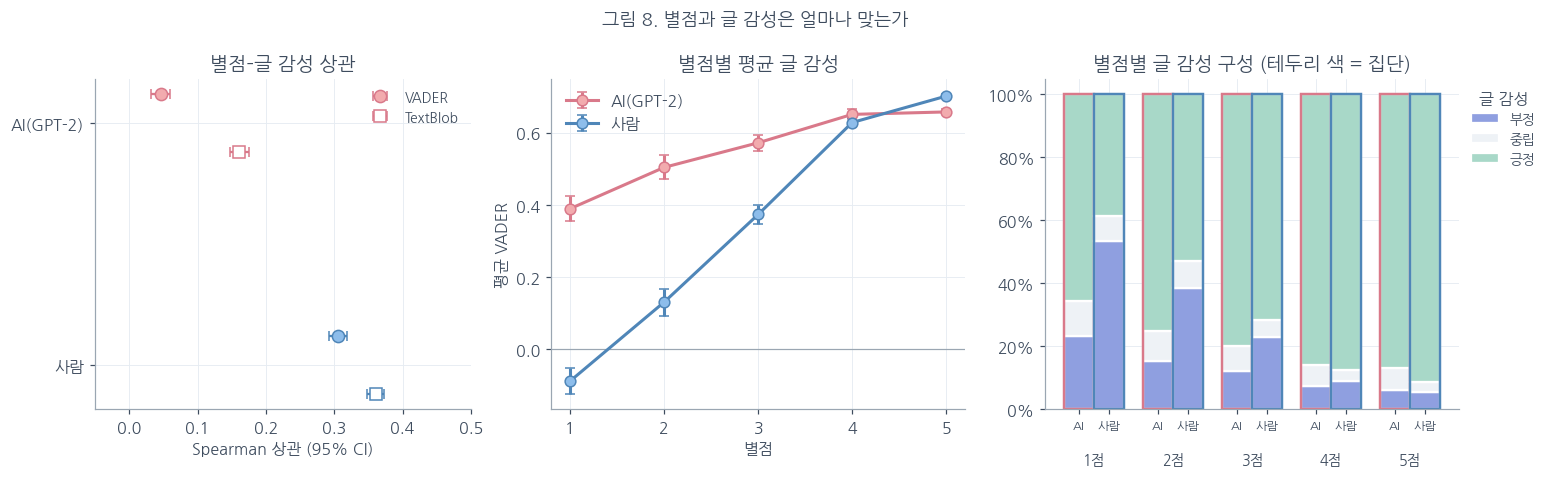

,도구,임계값,AI(GPT-2): 1~2점 긍정 비율,사람: 1~2점 긍정 비율,차이(%p)
0,VADER,0.05,0.7018,0.4539,24.7939
1,VADER,0.10,0.6944,0.4376,25.6754
2,VADER,0.20,0.6771,0.4056,27.1430
3,VADER,0.30,0.6345,0.3708,26.3713
4,VADER,0.50,0.5671,0.2871,27.9965
5,TextBlob,0.00,0.7365,0.5901,14.6441
6,TextBlob,0.05,0.6880,0.4792,20.8748
7,TextBlob,0.10,0.6251,0.3622,26.2902
8,TextBlob,0.20,0.4864,0.1701,31.6289
9,TextBlob,0.30,0.3269,0.0760,25.0927


In [ ]:
# %% 8. 감성·별점 정합성 (H1: AI는 별점과 상관없이 긍정적인가) -----------
df['star_sent'] = np.select([df['rating'] <= 2, df['rating'] == 3], ['부정', '중립'], '긍정')
df['vader_cat'] = np.select([df['vader'] >= 0.05, df['vader'] <= -0.05], ['긍정', '부정'], '중립')
df['tb_cat'] = np.select([df['textblob'] > 0.1, df['textblob'] < -0.1], ['긍정', '부정'], '중립')

def align_metrics(d):
    o = {'리뷰 수': len(d)}
    for tool, col in [('VADER', 'vader'), ('TextBlob', 'textblob')]:
        r, lo, hi = spearman_ci(d['rating'], d[col]); o[f'{tool} Spearman'] = r; o[f'{tool} 95%CI'] = f'[{lo:.3f}, {hi:.3f}]'
    lo_, hi_ = d[d['rating'] <= 2], d[d['rating'] >= 4]
    o['1~2점인데 글은 긍정(VADER)'] = (lo_['vader_cat'] == '긍정').mean()
    o['4~5점인데 글은 부정(VADER)'] = (hi_['vader_cat'] == '부정').mean()
    o['범주 불일치율(VADER)'] = (d['vader_cat'] != d['star_sent']).mean()
    o['과잉 긍정(VADER ≥ 0.9)'] = d['extreme_pos'].mean()
    return pd.Series(o)
align = pd.DataFrame({g: align_metrics(df[df['group'] == g]) for g in GROUPS})
display(export(align, '08_정합성_지표.csv'))

tests = []
for tool, col in [('VADER', 'vader'), ('TextBlob', 'textblob')]:
    da, dh = df[is_ai], df[~is_ai]
    ra, rh = spearmanr(da['rating'], da[col]).statistic, spearmanr(dh['rating'], dh[col]).statistic
    z, p = compare_spearman(ra, len(da), rh, len(dh))
    tests.append({'도구': tool, f'{AI} 상관': ra, f'{HU} 상관': rh, '차이(AI-사람)': ra - rh, 'z': z, 'p값': p})
tests = pd.DataFrame(tests); tests['p값 표기'] = tests['p값'].map(fmt_p)
display(export(tests.round(4), '08_상관차이_검정.csv', index=False))

fig, axs = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={'width_ratios': [1, 1.1, 1.1]})
yy = np.arange(len(GROUPS))[::-1]
for tool, col, off, filled in [('VADER', 'vader', 0.12, True), ('TextBlob', 'textblob', -0.12, False)]:
    for yi, g in zip(yy, GROUPS):
        d = df[df['group'] == g]; r, lo, hi = spearman_ci(d['rating'], d[col])
        axs[0].errorbar(r, yi + off, xerr=[[r - lo], [hi - r]], fmt='o' if filled else 's', color=EDGE[g], ms=8, capsize=3,
                        mfc=COLORS[g] if filled else 'white', mec=EDGE[g], label=tool if g == AI else None)
axs[0].set_yticks(yy, GROUPS); axs[0].set_xlim(-0.05, 0.5); axs[0].set_xlabel('Spearman 상관 (95% CI)')
axs[0].set_title('별점–글 감성 상관'); axs[0].legend(frameon=False, fontsize=9)
for g in GROUPS:
    s = df[df['group'] == g].groupby('rating')['vader'].agg(['mean', 'sem'])
    axs[1].errorbar(s.index, s['mean'], yerr=1.96 * s['sem'], marker='o', ms=7, lw=2, capsize=3, color=EDGE[g], mfc=COLORS[g], mec=EDGE[g], label=g)
axs[1].axhline(0, color=NEUTRAL_EDGE, lw=0.8); axs[1].set_xticks(range(1, 6)); axs[1].set_xlabel('별점'); axs[1].set_ylabel('평균 VADER')
axs[1].set_title('별점별 평균 글 감성'); axs[1].legend(frameon=False)
comp = pd.crosstab(df['rating'], [df['group'], df['vader_cat']], normalize='index')
x = np.arange(1, 6); w = 0.38
for i, g in enumerate(GROUPS):
    sub = pd.crosstab(df.loc[df['group'] == g, 'rating'], df.loc[df['group'] == g, 'vader_cat'], normalize='index').reindex(columns=['부정', '중립', '긍정'], fill_value=0)
    bottom = np.zeros(5)
    for cat_, col, ec in [('부정', PERI, PERI_EDGE), ('중립', '#EEF2F6', NEUTRAL_EDGE), ('긍정', MINT, MINT_EDGE)]:
        axs[2].bar(x + (i - 0.5) * w, sub[cat_].values, w, bottom=bottom, color=col, edgecolor='white', linewidth=1.5,
                   label=cat_ if i == 0 else None); bottom += sub[cat_].values
    axs[2].bar(x + (i - 0.5) * w, np.ones(5), w, fill=False, edgecolor=EDGE[g], linewidth=1.6)   # 집단 테두리
axs[2].set_xticks(np.r_[x - w / 2, x + w / 2], ['AI'] * 5 + ['사람'] * 5, fontsize=8)
for k in x: axs[2].text(k, -0.13, f'{k}점', ha='center', va='top', fontsize=9.5, transform=axs[2].get_xaxis_transform())
axs[2].yaxis.set_major_formatter(PercentFormatter(1)); axs[2].set_title('별점별 글 감성 구성 (테두리 색 = 집단)')
axs[2].legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0), title='글 감성')
fig.suptitle('그림 8. 별점과 글 감성은 얼마나 맞는가', y=1.04, fontsize=12)
savefig(fig, 'fig08_정합성.png')

# 임계값을 바꿔도 결론이 같은가 (강건성)
sens = []
for tool, col, ths in [('VADER', 'vader', [0.05, 0.1, 0.2, 0.3, 0.5]), ('TextBlob', 'textblob', [0.0, 0.05, 0.1, 0.2, 0.3])]:
    for th in ths:
        lowp = df[df['rating'] <= 2].groupby('group')[col].apply(lambda v: (v > th).mean()).reindex(GROUPS)
        sens.append({'도구': tool, '임계값': th, f'{AI}: 1~2점 긍정 비율': lowp[AI], f'{HU}: 1~2점 긍정 비율': lowp[HU], '차이(%p)': 100 * (lowp[AI] - lowp[HU])})
sens = pd.DataFrame(sens); display(export(sens.round(4), '08_임계값_민감도.csv', index=False))

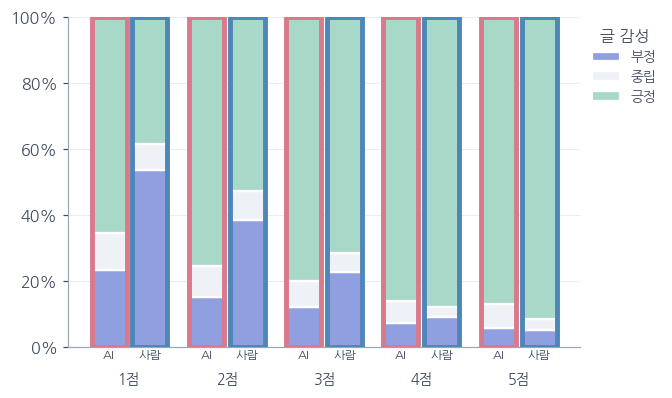

In [ ]:
# %% 8-1. 별점별 글 감성 구성 (그림 8 오른쪽 칸만 따로) ------------------------
from matplotlib.ticker import PercentFormatter
df['vader_cat'] = np.select([df['vader'] >= 0.05, df['vader'] <= -0.05], ['긍정', '부정'], '중립')

fig, ax = plt.subplots(figsize=(6, 3.9))
x = np.arange(1, 6); w = 0.36; gap = 0.06      # gap = AI·사람 막대 사이 간격
for i, g in enumerate(GROUPS):
    sub = pd.crosstab(df.loc[df['group'] == g, 'rating'], df.loc[df['group'] == g, 'vader_cat'], normalize='index').reindex(columns=['부정', '중립', '긍정'], fill_value=0)
    bottom = np.zeros(5)
    for cat_, col, ec in [('부정', PERI, PERI_EDGE), ('중립', '#EEF2F6', NEUTRAL_EDGE), ('긍정', MINT, MINT_EDGE)]:
        ax.bar(x + (i - 0.5) * (w + gap), sub[cat_].values, w, bottom=bottom, color=col, edgecolor='white', linewidth=1.5,
               label=cat_ if i == 0 else None); bottom += sub[cat_].values
    ax.bar(x + (i - 0.5) * (w + gap), np.ones(5), w, fill=False, edgecolor=EDGE[g], linewidth=3.2, zorder=3)   # 집단 테두리 (두껍게)
ax.set_xticks(np.r_[x - (w + gap) / 2, x + (w + gap) / 2], ['AI'] * 5 + ['사람'] * 5, fontsize=8)
ax.tick_params(axis='x', length=0, pad=2)                       # AI·사람 글자를 그래프에 붙임
for k in x:                                                     # 1점~5점: 예전 -0.13 → -0.075로 그래프에 더 가깝게
    ax.text(k, -0.075, f'{k}점', ha='center', va='top', fontsize=9.5, transform=ax.get_xaxis_transform())
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0), title='글 감성')
savefig(fig, 'fig08c_별점별_감성구성.png')

,AI(GPT-2),사람,차이(%p),효과크기 r
추천·권유 표현,0.1948,0.1371,5.7754,0.0578
상투적 칭찬 문구,0.2264,0.1166,10.9806,0.1098
과잉 긍정,0.3735,0.3200,5.3521,0.0535
대문자 강조 포함,0.0701,0.1668,-9.6781,-0.0968
가족 언급,0.1610,0.1702,-0.9190,-0.0092
숫자 포함,0.1914,0.3185,-12.7068,-0.1271
사용 기간 표현,0.0907,0.1488,-5.8130,-0.0581
가격·단위 표현,0.0320,0.0760,-4.4018,-0.0440
단점·역접 표현,0.3339,0.4516,-11.7710,-0.1177
망설임 표현,0.1018,0.1585,-5.6681,-0.0567


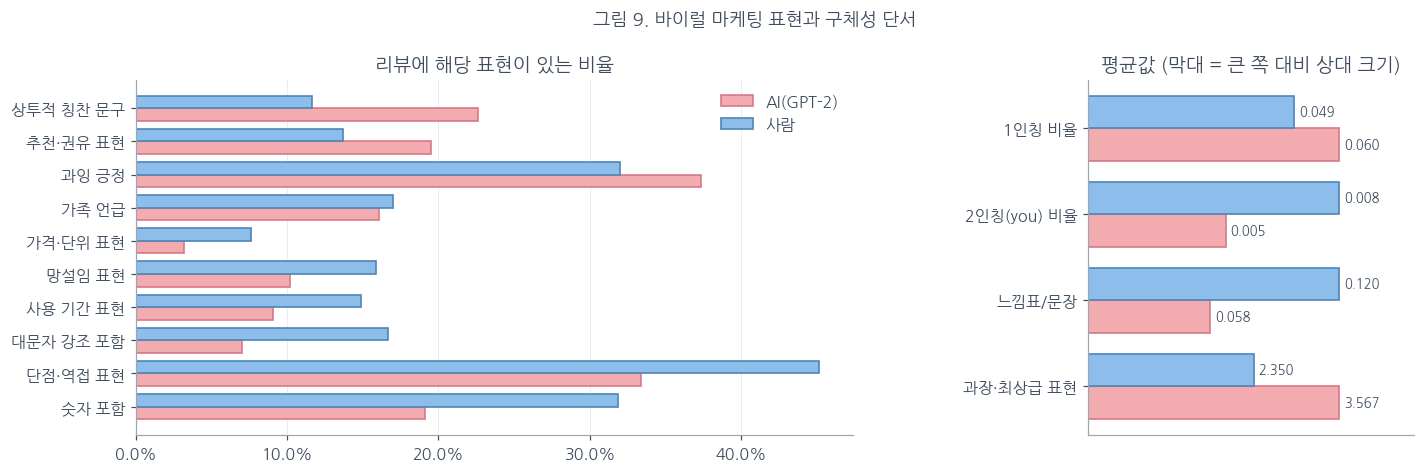

In [ ]:
# %% 9. 바이럴 마케팅 표현과 구체성 ------------------------------------
VIRAL = ['recommend', 'cliche', 'extreme_pos', 'allcaps', 'family', 'has_digit', 'duration', 'price_unit', 'contrast', 'hedge']
cont_viral = ['hype_rate', 'exclam_per_sent', 'second_person', 'first_person']
vt = pd.DataFrame({g: df.loc[df['group'] == g, VIRAL].mean() for g in GROUPS}); vt.index = [KO[c] for c in VIRAL]
vt['차이(%p)'] = 100 * (vt[AI] - vt[HU]); vt['효과크기 r'] = [stat.loc[c, '효과크기 r'] for c in VIRAL]
display(export(vt.round(4), '09_바이럴_구체성_비율.csv'))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2.2, 1], 'wspace': 0.45})
order = vt.sort_values('차이(%p)').index; y = np.arange(len(order))
for i, g in enumerate(GROUPS): axs[0].barh(y + (i - 0.5) * 0.38, vt.loc[order, g], 0.38, color=COLORS[g], edgecolor=EDGE[g], label=g, **BAR_KW)
axs[0].set_yticks(y, order); axs[0].xaxis.set_major_formatter(PercentFormatter(1)); axs[0].grid(axis='y', visible=False)
axs[0].set_title('리뷰에 해당 표현이 있는 비율'); axs[0].legend(frameon=False, loc='upper right')
mv = pd.DataFrame({g: df.loc[df['group'] == g, cont_viral].mean() for g in GROUPS}); mv.index = [KO[c] for c in cont_viral]
mvn = mv.div(mv.max(1), axis=0)
y = np.arange(len(mv))
for i, g in enumerate(GROUPS):
    axs[1].barh(y + (i - 0.5) * 0.38, mvn[g], 0.38, color=COLORS[g], edgecolor=EDGE[g], **BAR_KW)
    for yi, v, raw_v in zip(y, mvn[g], mv[g]): axs[1].text(v + 0.02, yi + (i - 0.5) * 0.38, f'{raw_v:.3f}', va='center', fontsize=8.5)
axs[1].set_yticks(y, mv.index); axs[1].set_xlim(0, 1.3); axs[1].set_xticks([]); axs[1].grid(False)
axs[1].set_title('평균값 (막대 = 큰 쪽 대비 상대 크기)')
fig.suptitle('그림 9. 바이럴 마케팅 표현과 구체성 단서', y=1.03, fontsize=12)
savefig(fig, 'fig09_바이럴_구체성.png')

,통념,피처,출처,통념상 큰 쪽,실제 효과크기 r,실제 큰 쪽,판정
0,1인칭(I·my)이 많으면 사람,1인칭 비율,Jakesch 외(2023),사람,0.131,AI(GPT-2),통념과 반대
1,가족 이야기가 있으면 사람,가족 언급,Jakesch 외(2023),사람,-0.009,사람,차이 거의 없음
2,사용 기간 등 경험담이 있으면 사람,사용 기간 표현,Jakesch 외(2023),사람,-0.058,사람,차이 거의 없음
3,축약형(구어체)이 많으면 사람,축약형 비율,일반 통념,사람,-0.070,사람,차이 거의 없음
4,숫자·가격 등 구체적이면 사람,숫자 포함,일반 통념,사람,-0.127,사람,통념과 일치
5,단점도 말하면 사람,단점·역접 표현,일반 통념,사람,-0.118,사람,통념과 일치
6,과장·최상급이 많으면 AI,과장·최상급 표현,일반 통념,AI(GPT-2),0.124,AI(GPT-2),통념과 일치
7,추천·권유가 많으면 AI,추천·권유 표현,일반 통념,AI(GPT-2),0.058,AI(GPT-2),차이 거의 없음
8,느낌표가 많으면 AI,느낌표/문장,일반 통념,AI(GPT-2),-0.097,사람,차이 거의 없음
9,같은 말을 반복하면 AI,반복 3단어 비율,일반 통념,AI(GPT-2),0.191,AI(GPT-2),통념과 일치


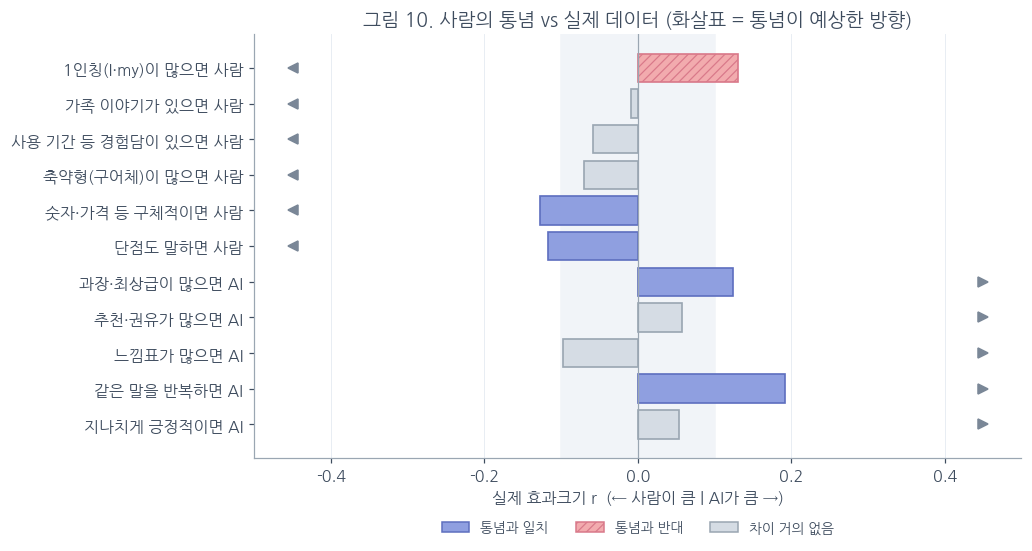

In [ ]:
# %% 10. 사람의 통념 점검: 사람들이 믿는 판단 기준은 맞는가 --------------
# 통념 출처: Jakesch et al. (2023, PNAS) — 1인칭·가족·개인 경험이 있으면 사람이 썼다고 판단
#           그 밖은 흔한 소비자 통념 (가짜 리뷰 = 과장, 반복, 감탄, 구체성 부족, 단점 없음)
BELIEFS = [  # (통념, 피처, 통념상 큰 쪽, 출처)
    ('1인칭(I·my)이 많으면 사람', 'first_person', HU, 'Jakesch 외(2023)'),
    ('가족 이야기가 있으면 사람', 'family', HU, 'Jakesch 외(2023)'),
    ('사용 기간 등 경험담이 있으면 사람', 'duration', HU, 'Jakesch 외(2023)'),
    ('축약형(구어체)이 많으면 사람', 'contraction_rate', HU, '일반 통념'),
    ('숫자·가격 등 구체적이면 사람', 'has_digit', HU, '일반 통념'),
    ('단점도 말하면 사람', 'contrast', HU, '일반 통념'),
    ('과장·최상급이 많으면 AI', 'hype_rate', AI, '일반 통념'),
    ('추천·권유가 많으면 AI', 'recommend', AI, '일반 통념'),
    ('느낌표가 많으면 AI', 'exclam_per_sent', AI, '일반 통념'),
    ('같은 말을 반복하면 AI', 'rep_trigram', AI, '일반 통념'),
    ('지나치게 긍정적이면 AI', 'extreme_pos', AI, '일반 통념'),
]
rows = []
for belief, c, big, src in BELIEFS:
    r = stat.loc[c, '효과크기 r']; expect = 1 if big == AI else -1
    verdict = '차이 거의 없음' if abs(r) < R_TH else ('통념과 일치' if np.sign(r) == expect else '통념과 반대')
    rows.append({'통념': belief, '피처': KO[c], '출처': src, '통념상 큰 쪽': big, '실제 효과크기 r': r,
                 '실제 큰 쪽': AI if r > 0 else HU, '판정': verdict})
belief_tbl = pd.DataFrame(rows); display(export(belief_tbl.round(3), '10_통념점검.csv', index=False))

fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(belief_tbl))[::-1]
vcol = {'통념과 일치': (PERI, PERI_EDGE, ''), '통념과 반대': (COLORS[AI], EDGE[AI], '////'), '차이 거의 없음': (NEUTRAL, NEUTRAL_EDGE, '')}
for yi, (_, r) in zip(yy, belief_tbl.iterrows()):
    fc, ec, ht = vcol[r['판정']]
    ax.barh(yi, r['실제 효과크기 r'], color=fc, edgecolor=ec, hatch=ht, **BAR_KW)
for yi, (_, r) in zip(yy, belief_tbl.iterrows()):
    ax.plot(0.45 * (1 if r['통념상 큰 쪽'] == AI else -1), yi, marker='>' if r['통념상 큰 쪽'] == AI else '<', color=INK2, ms=7)
ax.axvspan(-R_TH, R_TH, color='#F1F4F8', zorder=0); ax.axvline(0, color=NEUTRAL_EDGE, lw=0.8)
ax.set_yticks(yy, belief_tbl['통념']); ax.set_xlim(-0.5, 0.5); ax.grid(axis='y', visible=False)
ax.set_xlabel('실제 효과크기 r  (← 사람이 큼 | AI가 큼 →)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=fc, edgecolor=ec, hatch=ht, label=k) for k, (fc, ec, ht) in vcol.items()], frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
ax.set_title('그림 10. 사람의 통념 vs 실제 데이터 (화살표 = 통념이 예상한 방향)')
savefig(fig, 'fig10_통념점검.png')

,도서,의류·신발,전자제품,가정·주방,전자책,영화·TV,반려동물,스포츠,공구,장난감
어휘 다양성(TTR40),-0.769,-0.700,-0.709,-0.738,-0.717,-0.807,-0.659,-0.736,-0.708,-0.709
평균 단어 길이,-0.435,-0.311,-0.429,-0.408,-0.343,-0.463,-0.461,-0.427,-0.417,-0.423
어휘 다양성(MATTR),-0.480,-0.272,-0.358,-0.295,-0.536,-0.528,-0.269,-0.331,-0.308,-0.301
문장당 단어 수,-0.275,-0.345,-0.287,-0.241,-0.366,-0.374,-0.279,-0.301,-0.261,-0.320
반복 3단어 비율,0.284,0.134,0.172,0.145,0.285,0.287,0.157,0.145,0.166,0.136
단어 수,-0.180,-0.192,-0.203,-0.196,-0.177,-0.173,-0.190,-0.200,-0.185,-0.184
2인칭(you) 비율,-0.175,-0.167,-0.162,-0.178,-0.193,-0.137,-0.137,-0.161,-0.191,-0.148
부정어 포함,-0.168,-0.184,-0.111,-0.166,-0.204,-0.164,-0.156,-0.160,-0.126,-0.209
문장별 감성 변동,-0.296,-0.070,-0.082,-0.139,-0.329,-0.235,-0.116,-0.080,-0.072,-0.186
쉼표/문장,-0.170,-0.095,-0.141,-0.099,-0.253,-0.136,-0.188,-0.153,-0.128,-0.196


,AI(GPT-2),사람,차이(AI-사람)
도서,0.007,0.207,-0.200
의류·신발,0.109,0.397,-0.288
전자제품,0.049,0.315,-0.266
가정·주방,0.057,0.404,-0.347
전자책,0.018,0.198,-0.180
영화·TV,0.057,0.282,-0.225
반려동물,0.090,0.374,-0.283
스포츠,0.062,0.325,-0.263
공구,0.005,0.314,-0.309
장난감,0.037,0.313,-0.276


상품군 10개 중 전체와 같은 방향인 비율:
어휘 다양성(TTR40)    100%
평균 단어 길이         100%
어휘 다양성(MATTR)    100%
문장당 단어 수         100%
반복 3단어 비율        100%
단어 수             100%
2인칭(you) 비율      100%
부정어 포함           100%
문장별 감성 변동        100%
쉼표/문장            100%


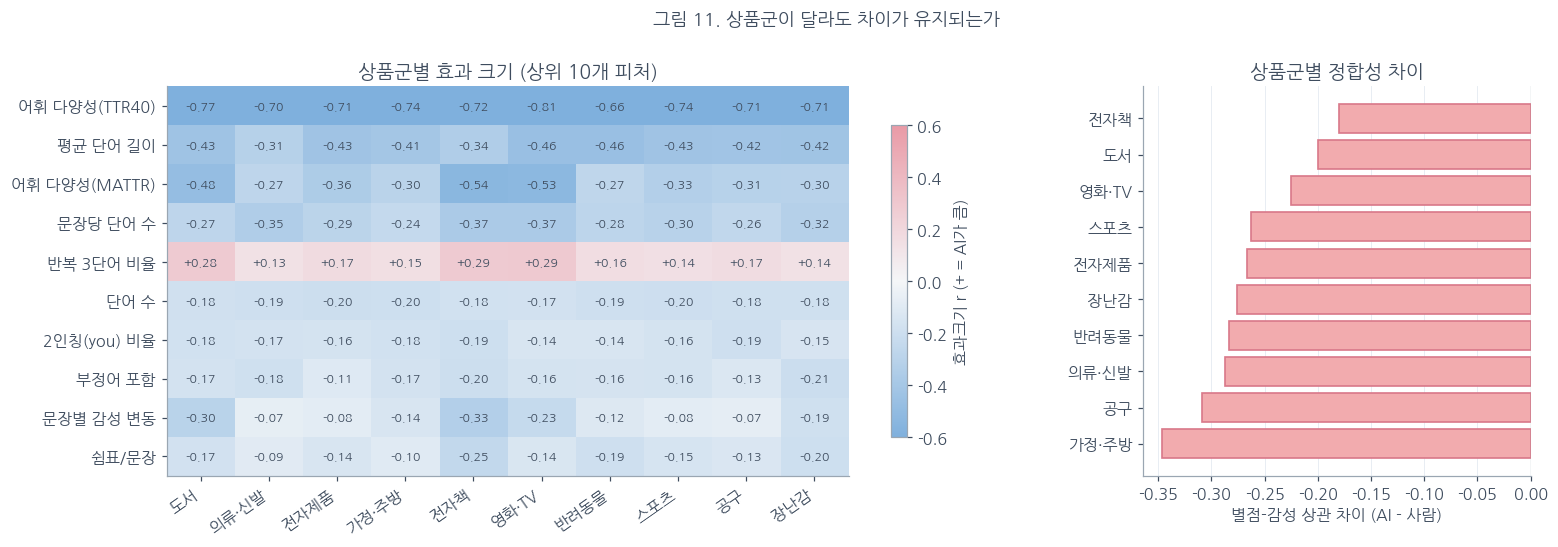

In [ ]:
# %% 11. 상품군별 차이 ---------------------------------------------------
top_feats = stat['효과크기 r'].abs().sort_values(ascending=False).index[:10].tolist()
cat_eff = pd.DataFrame({CAT_KO.get(cat_, cat_): {KO[c]: rank_biserial(sub.loc[sub['group'] == AI, c], sub.loc[sub['group'] == HU, c]) for c in top_feats}
                        for cat_, sub in df.groupby('category')})
cat_sp = pd.DataFrame({CAT_KO.get(cat_, cat_): {g: spearmanr(sub.loc[sub['group'] == g, 'rating'], sub.loc[sub['group'] == g, 'vader']).statistic for g in GROUPS}
                       for cat_, sub in df.groupby('category')}).T
cat_sp['차이(AI-사람)'] = cat_sp[AI] - cat_sp[HU]
display(export(cat_eff.round(3), '11_상품군별_효과크기.csv')); display(export(cat_sp.round(3), '11_상품군별_정합성.csv'))
same_dir = (np.sign(cat_eff).eq(np.sign(stat.set_index('이름').loc[cat_eff.index, '효과크기 r']), axis=0)).mean(1)
print('상품군 10개 중 전체와 같은 방향인 비율:'); print(same_dir.map('{:.0%}'.format).to_string())

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [2.2, 1]})
im = axs[0].imshow(cat_eff.values, cmap=CMAP_DIV, vmin=-0.6, vmax=0.6, aspect='auto'); axs[0].grid(False)
axs[0].set_yticks(range(len(cat_eff)), cat_eff.index); axs[0].set_xticks(range(cat_eff.shape[1]), cat_eff.columns, rotation=35, ha='right')
for i in range(cat_eff.shape[0]):
    for j in range(cat_eff.shape[1]):
        v = cat_eff.iloc[i, j]; axs[0].text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=8, color=INK)
fig.colorbar(im, ax=axs[0], shrink=0.8, label='효과크기 r (+ = AI가 큼)'); axs[0].set_title('상품군별 효과 크기 (상위 10개 피처)')
s = cat_sp.sort_values('차이(AI-사람)')
axs[1].barh(s.index, s['차이(AI-사람)'], color=COLORS[AI], edgecolor=EDGE[AI], **BAR_KW); axs[1].axvline(0, color=NEUTRAL_EDGE, lw=0.8); axs[1].grid(axis='y', visible=False)
axs[1].set_xlabel('별점-감성 상관 차이 (AI - 사람)'); axs[1].set_title('상품군별 정합성 차이')
fig.suptitle('그림 11. 상품군이 달라도 차이가 유지되는가', y=1.03, fontsize=12)
savefig(fig, 'fig11_상품군별.png')

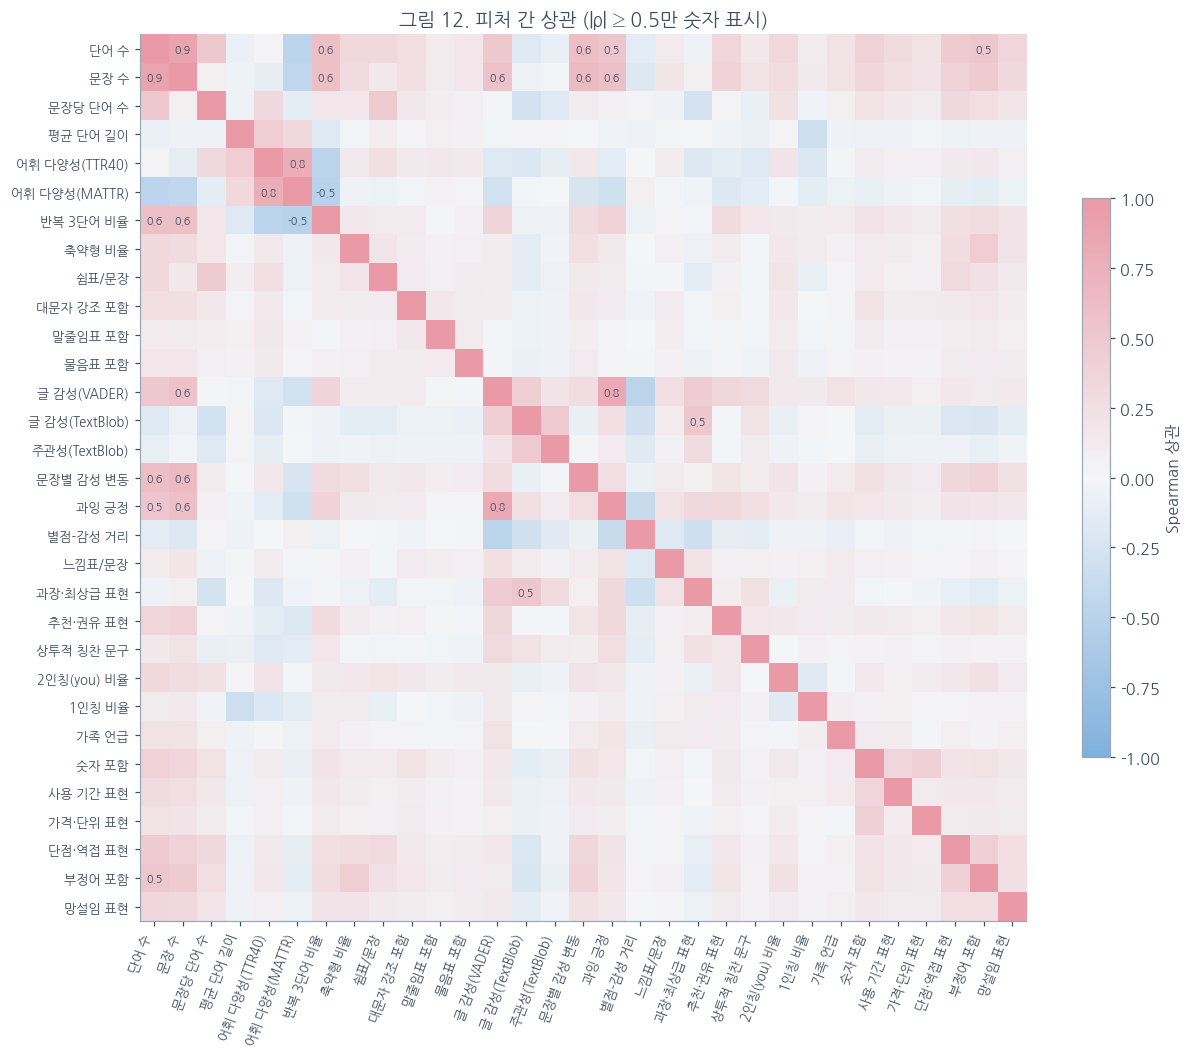

,피처 A,피처 B,Spearman ρ
0,단어 수,문장 수,0.890
1,어휘 다양성(TTR40),어휘 다양성(MATTR),0.783
2,글 감성(VADER),과잉 긍정,0.824


선정된 피처 15개: 평균 단어 길이, 어휘 다양성(MATTR), 문장당 단어 수, 반복 3단어 비율, 단어 수, 2인칭(you) 비율, 부정어 포함, 문장별 감성 변동, 쉼표/문장, 1인칭 비율, 숫자 포함, 과장·최상급 표현, 단점·역접 표현, 주관성(TextBlob), 상투적 칭찬 문구


In [ ]:
# %% 12. 피처 간 상관과 후보 선정 ---------------------------------------
corr = df[FEATS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr.values, cmap=CMAP_DIV, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(FEATS)), [KO[c] for c in FEATS], rotation=70, ha='right', fontsize=8.5)
ax.set_yticks(range(len(FEATS)), [KO[c] for c in FEATS], fontsize=8.5)
for i in range(len(FEATS)):
    for j in range(len(FEATS)):
        if i != j and abs(corr.iloc[i, j]) >= 0.5:
            ax.text(j, i, f'{corr.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7, color=INK, weight='bold' if abs(corr.iloc[i, j]) >= CORR_TH else 'normal')
fig.colorbar(im, ax=ax, shrink=0.6, label='Spearman 상관'); ax.set_title('그림 12. 피처 간 상관 (|ρ| ≥ 0.5만 숫자 표시)')
savefig(fig, 'fig12_피처상관.png')

# 선정 규칙: (1) |r| ≥ 0.1  (2) 서로 |ρ| ≥ 0.7이면 |r|이 작은 쪽 제외
#           (3) TextBlob 감성은 VADER와 같은 개념이라 확인용으로만 사용, TTR40은 결측이 많아 MATTR로 대체
EXCLUDE_FIXED = {'textblob': '감성 확인용 (VADER와 같은 개념)', 'ttr40': '40단어 미만 결측 → MATTR로 대체'}
reason = {}
cands = stat['효과크기 r'].abs().sort_values(ascending=False).index.tolist()
kept = []
for c in cands:
    if c in EXCLUDE_FIXED: reason[c] = EXCLUDE_FIXED[c]; continue
    if abs(stat.loc[c, '효과크기 r']) < R_TH: reason[c] = f'효과 작음 (|r| < {R_TH})'; continue
    clash = [k for k in kept if abs(corr.loc[c, k]) >= CORR_TH]
    if clash: reason[c] = f"{KO[clash[0]]}와 상관 {corr.loc[c, clash[0]]:.2f} (효과가 더 작아 제외)"; continue
    kept.append(c); reason[c] = '선정'
high_pairs = pd.DataFrame([(KO[a], KO[b], corr.loc[a, b]) for i, a in enumerate(FEATS) for b in FEATS[i + 1:] if abs(corr.loc[a, b]) >= CORR_TH],
                          columns=['피처 A', '피처 B', 'Spearman ρ'])
display(export(high_pairs.round(3), '12_높은상관_쌍.csv', index=False))
print(f'선정된 피처 {len(kept)}개:', ', '.join(KO[c] for c in kept))

,이름,묶음,AI(GPT-2) 평균,사람 평균,효과크기 r,방향,|r|,EDA 순위(전체),선정 여부,EDA 순위(선정 피처 내)
코드,,,,,,,,,,
ttr40,어휘 다양성(TTR40),어휘·문체,0.7248,0.8331,-0.7262,사람이 큼,0.7262,1,40단어 미만 결측 → MATTR로 대체,NaN
avg_word_len,평균 단어 길이,어휘·문체,3.9371,4.2095,-0.4011,사람이 큼,0.4011,2,선정,1.0
mattr,어휘 다양성(MATTR),어휘·문체,0.8501,0.9060,-0.3666,사람이 큼,0.3666,3,선정,2.0
words_per_sent,문장당 단어 수,길이·구조,10.8755,13.9436,-0.3037,사람이 큼,0.3037,4,선정,3.0
rep_trigram,반복 3단어 비율,어휘·문체,0.0332,0.0035,0.1913,AI가 큼,0.1913,5,선정,4.0
n_words,단어 수,길이·구조,56.1372,72.9425,-0.1858,사람이 큼,0.1858,6,선정,5.0
second_person,2인칭(you) 비율,바이럴 표현,0.0046,0.0083,-0.1657,사람이 큼,0.1657,7,선정,6.0
negation,부정어 포함,구체성·경험,0.3778,0.5429,-0.1651,사람이 큼,0.1651,8,선정,7.0
sent_sd,문장별 감성 변동,감성·정합성,0.1991,0.2449,-0.1641,사람이 큼,0.1641,9,선정,8.0


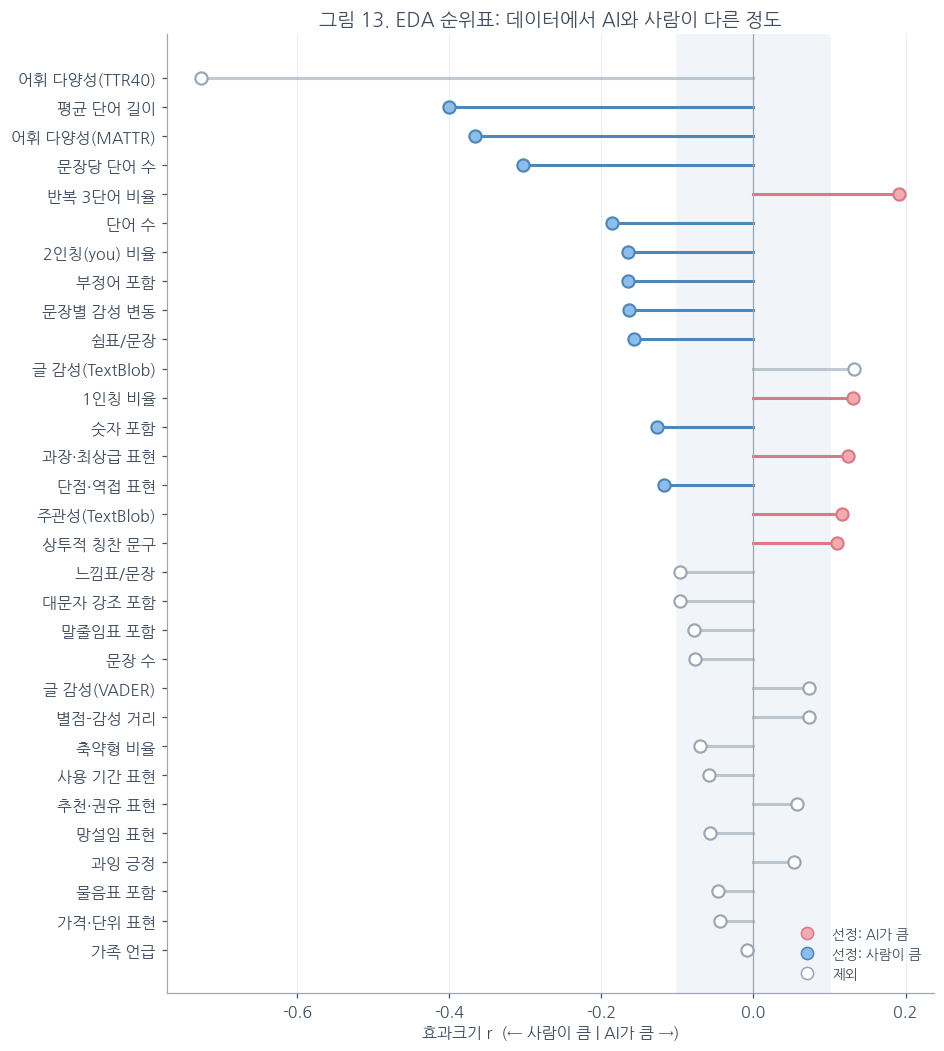

In [ ]:
# %% 13. EDA 순위표: "데이터가 말하는 판단 기준" (나중에 SHAP 순위와 비교) --
rank = stat[['이름', '묶음', f'{AI} 평균', f'{HU} 평균', '효과크기 r', '방향']].copy()
rank['|r|'] = rank['효과크기 r'].abs()
rank = rank.sort_values('|r|', ascending=False)
rank['EDA 순위(전체)'] = np.arange(1, len(rank) + 1)
rank['선정 여부'] = [reason[c] for c in rank.index]
sel = rank[rank['선정 여부'] == '선정'].copy(); sel['EDA 순위(선정 피처 내)'] = np.arange(1, len(sel) + 1)
rank = rank.join(sel[['EDA 순위(선정 피처 내)']])
rank.index.name = '코드'
display(export(rank.round(4), 'eda_ranking.csv'))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(rank) + 1.4))
yy = np.arange(len(rank))[::-1]
for yi, (c, r) in zip(yy, rank.iterrows()):
    chosen = r['선정 여부'] == '선정'
    fc, ec = DIR_COLORS[r['방향']] if chosen else (NEUTRAL, NEUTRAL_EDGE)
    ax.plot([0, r['효과크기 r']], [yi, yi], color=ec, lw=2, alpha=1 if chosen else 0.6)
    ax.plot(r['효과크기 r'], yi, 'o', mfc=fc if chosen else 'white', mec=ec, mew=1.4, ms=8)
ax.axvspan(-R_TH, R_TH, color='#F1F4F8', zorder=0); ax.axvline(0, color=NEUTRAL_EDGE, lw=0.8)
ax.set_yticks(yy, rank['이름']); ax.grid(axis='y', visible=False)
ax.set_xlabel('효과크기 r  (← 사람이 큼 | AI가 큼 →)')
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', mfc=COLORS[AI], mec=EDGE[AI], ms=8, label='선정: AI가 큼'),
                   plt.Line2D([], [], marker='o', ls='', mfc=COLORS[HU], mec=EDGE[HU], ms=8, label='선정: 사람이 큼'),
                   plt.Line2D([], [], marker='o', ls='', mfc='white', mec=NEUTRAL_EDGE, ms=8, label='제외')],
          frameon=False, fontsize=9, loc='lower right')
ax.set_title('그림 13. EDA 순위표: 데이터에서 AI와 사람이 다른 정도')
savefig(fig, 'fig13_EDA순위표.png')

In [ ]:
# %% 14. 가설 점검, 요약, 저장 ------------------------------------------
v_ai, v_hu = align.loc['VADER Spearman', AI], align.loc['VADER Spearman', HU]
p_v = tests.loc[tests['도구'] == 'VADER', 'p값'].iloc[0]
low_ai, low_hu = align.loc['1~2점인데 글은 긍정(VADER)', AI], align.loc['1~2점인데 글은 긍정(VADER)', HU]
h1 = '지지' if (v_ai < v_hu and p_v < 0.05 and low_ai > low_hu) else '기각/부분'
style_checks = {'MATTR': stat.loc['mattr', '효과크기 r'] <= -R_TH, '평균 단어 길이': stat.loc['avg_word_len', '효과크기 r'] <= -R_TH,
                '반복 3단어': stat.loc['rep_trigram', '효과크기 r'] >= R_TH}
h2 = '지지' if all(style_checks.values()) else ('부분 지지' if any(style_checks.values()) else '기각')
n_opp = (belief_tbl['판정'] == '통념과 반대').sum(); n_none = (belief_tbl['판정'] == '차이 거의 없음').sum(); n_ok = (belief_tbl['판정'] == '통념과 일치').sum()
hyp = pd.DataFrame([
    {'가설': 'H1 과잉 긍정: AI 리뷰는 별점과 상관없이 긍정적이다', '판정(EDA)': h1,
     '근거': f'Spearman {v_ai:.3f} vs {v_hu:.3f} ({fmt_p(p_v)}), 1~2점인데 글은 긍정 {low_ai:.1%} vs {low_hu:.1%}'},
    {'가설': 'H2 문체: AI 리뷰는 어휘 다양성이 낮고 반복이 많고 단어가 짧다', '판정(EDA)': h2,
     '근거': ', '.join(f"{k} {'✓' if v else '✗'}" for k, v in style_checks.items())},
    {'가설': 'H3 EDA–XAI: 모델의 판단 기준은 EDA 차이와 대체로 일치한다', '판정(EDA)': 'XAI 단계에서 검증', '근거': 'eda_ranking.csv를 SHAP 순위와 비교 예정'},
    {'가설': 'H4 통념: 사람들의 판단 기준은 실제 차이와 다르다', '판정(EDA)': '지지' if n_opp + n_none >= 3 else '부분 지지',
     '근거': f'통념 {len(belief_tbl)}개 중 일치 {n_ok}, 반대 {n_opp}, 차이 없음 {n_none}'},
    {'가설': '전처리: 정제가 형식 흔적 누수를 줄인다', '판정(EDA)': '지지' if auc_surf_cln < auc_surf_raw - 0.05 else '확인 필요',
     '근거': f'형식 흔적만 쓴 AUC {auc_surf_raw:.3f} → {auc_surf_cln:.3f}'},
])
display(export(hyp, '14_가설점검.csv', index=False))

def fmt(c): return f"{KO[c]}({stat.loc[c, '효과크기 r']:+.2f})"
lines = ['# EDA v2 핵심 결과 (GPT-2 AI vs 사람)', '',
         '## 1. 데이터와 전처리',
         f"- 원본 {len(raw):,}건 → 정제 후 {len(df):,}건 (" + ', '.join(f'{g} {int((df.group == g).sum()):,}' for g in GROUPS) + ')',
         '- 단계별: ' + ' → '.join(f"{n} {int(step_tbl.loc[n, '합계']):,}" for n, _ in steps),
         f"- 끝 문장이 잘려 제거된 비율: {AI} {trunc[AI]:.1%}, {HU} {trunc[HU]:.1%}",
         f"- 통제 변수 균형: 별점 Cramér V {ctrl.iloc[0]:.3f}, 상품군 {ctrl.iloc[1]:.3f}",
         f"- 누수 점검: 형식 흔적만으로 AUC {auc_surf_raw:.3f} → 정제 후 {auc_surf_cln:.3f}",
         f"- TF-IDF AUC: 원문 {auc_tf_raw:.3f}, 정제 {auc_tf_cln:.3f}, 정제+불용어 제거 {auc_tf_nostop:.3f} (판별 상위 50단어 중 불용어 {sw_share:.0%})", '',
         '## 2. 별점–감성 정합성',
         f"- VADER Spearman: {AI} {v_ai:.3f}, {HU} {v_hu:.3f} ({fmt_p(p_v)}) / TextBlob: {align.loc['TextBlob Spearman', AI]:.3f}, {align.loc['TextBlob Spearman', HU]:.3f}",
         f"- 1~2점인데 글은 긍정: {low_ai:.1%} vs {low_hu:.1%} / 과잉 긍정(VADER ≥ 0.9): {align.loc['과잉 긍정(VADER ≥ 0.9)', AI]:.1%} vs {align.loc['과잉 긍정(VADER ≥ 0.9)', HU]:.1%}", '',
         '## 3. 차이가 큰 피처 (효과크기 r, + = AI가 큼)',
         '- AI가 큼: ' + ', '.join(fmt(c) for c in rank.index if rank.loc[c, '효과크기 r'] >= R_TH),
         '- 사람이 큼: ' + ', '.join(fmt(c) for c in rank.index if rank.loc[c, '효과크기 r'] <= -R_TH),
         '- 차이 작음: ' + ', '.join(KO[c] for c in rank.index if abs(rank.loc[c, '효과크기 r']) < R_TH), '',
         '## 4. 사람의 통념 점검'] + [f"- {r['통념']}: {r['판정']} (r = {r['실제 효과크기 r']:+.2f})" for _, r in belief_tbl.iterrows()] + [
         '', f'## 5. 선정된 피처 {len(kept)}개', '- ' + ', '.join(KO[c] for c in kept), '',
         '## 6. 가설 점검'] + [f"- {r['가설']} → {r['판정(EDA)']} ({r['근거']})" for _, r in hyp.iterrows()]
report = '\n'.join(lines); (OUT / '00_핵심결과_요약.md').write_text(report, encoding='utf-8'); print(report)

keep_cols = ['review_id', 'label', 'group', 'category', 'rating', 'text_', 'text_clean', 'was_truncated'] + FEATS
df[keep_cols].rename(columns={'text_': 'text_raw'}).to_csv(OUT / 'eda_features.csv', index=False, encoding='utf-8-sig')
pd.Series(kept, name='selected_feature').to_csv(OUT / 'selected_features.csv', index=False)

zip_path = Path('EDA_v2_결과.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()): z.write(f, arcname=f'eda_v2_results/{f.name}')
print('\n저장 완료:', zip_path, f'({zip_path.stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    from google.colab import files; files.download(str(zip_path))

,가설,판정(EDA),근거
0,H1 과잉 긍정: AI 리뷰는 별점과 상관없이 긍정적이다,지지,"Spearman 0.046 vs 0.306 (p < 0.001), 1~2점인데 글은..."
1,H2 문체: AI 리뷰는 어휘 다양성이 낮고 반복이 많고 단어가 짧다,지지,"MATTR ✓, 평균 단어 길이 ✓, 반복 3단어 ✓"
2,H3 EDA–XAI: 모델의 판단 기준은 EDA 차이와 대체로 일치한다,XAI 단계에서 검증,eda_ranking.csv를 SHAP 순위와 비교 예정
3,H4 통념: 사람들의 판단 기준은 실제 차이와 다르다,지지,"통념 11개 중 일치 4, 반대 1, 차이 없음 6"
4,전처리: 정제가 형식 흔적 누수를 줄인다,지지,형식 흔적만 쓴 AUC 0.846 → 0.599


# EDA v2 핵심 결과 (GPT-2 AI vs 사람)

## 1. 데이터와 전처리
- 원본 40,432건 → 정제 후 40,214건 (AI(GPT-2) 20,052, 사람 20,162)
- 단계별: 원본 40,432 → 비영어 제거 40,409 → 3단어 미만 제거 40,318 → 라벨 안 중복 제거 40,219 → AI·사람 양쪽 문장 제거 40,217 → 근사 중복 제거 40,214
- 끝 문장이 잘려 제거된 비율: AI(GPT-2) 62.6%, 사람 6.7%
- 통제 변수 균형: 별점 Cramér V 0.013, 상품군 0.000
- 누수 점검: 형식 흔적만으로 AUC 0.846 → 정제 후 0.599
- TF-IDF AUC: 원문 0.986, 정제 0.975, 정제+불용어 제거 0.948 (판별 상위 50단어 중 불용어 84%)

## 2. 별점–감성 정합성
- VADER Spearman: AI(GPT-2) 0.046, 사람 0.306 (p < 0.001) / TextBlob: 0.161, 0.361
- 1~2점인데 글은 긍정: 70.2% vs 45.4% / 과잉 긍정(VADER ≥ 0.9): 37.3% vs 32.0%

## 3. 차이가 큰 피처 (효과크기 r, + = AI가 큼)
- AI가 큼: 반복 3단어 비율(+0.19), 글 감성(TextBlob)(+0.13), 1인칭 비율(+0.13), 과장·최상급 표현(+0.12), 주관성(TextBlob)(+0.12), 상투적 칭찬 문구(+0.11)
- 사람이 큼: 어휘 다양성(TTR40)(-0.73), 평균 단어 길이(-0.40), 어휘 다양성(MATTR)(-0.37), 문장당 단어 수(-0.30), 단어 수(-0.19), 2인칭(you) 비율(-0.17), 부정어 포함(-0.17), 문장별 감성 변동(-0.16), 쉼표/문장(-0.16), 숫자 포함(-0.13), 단점·역접 표현(-0.12)
- 차이 작음: 느낌표/문장, 대문자 강조 포함, 말줄임표 포함, 문장 수, 글 감성(VADER), 별점-감

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>